# Sales Forecasting – 90-Day Daily Forecast (End-to-End ML Project)

**Goal:** predict the company's **total daily sales for the next 90 days (about 3 months)** using regression models.

**Pipeline:** Data understanding → Cleaning → EDA → Correlation → Feature engineering → Feature selection →
Time-based split → Compare *all* regression models → Evaluation → Hyper-parameter tuning → Final model selection →
Save model → FastAPI (Docker / Render) → Streamlit UI.

**Important idea – this is a *time-series regression* problem.** Rows are ordered in time, so we must never shuffle the data
or let the model see the future. Every split, feature and metric in this notebook respects that rule.

In [1]:
import sys, os, json, time, warnings, inspect, hashlib, datetime as dt
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import joblib

sys.path.insert(0, "../api")           # shared feature-engineering code (also used by the API)
import forecast_core as fc

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams.update({"figure.dpi": 100, "axes.titleweight": "bold", "axes.titlesize": 12})
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

os.makedirs("../docs/figures", exist_ok=True)
os.makedirs("../api/artifacts", exist_ok=True)
def savefig(name):
    plt.savefig(f"../docs/figures/{name}.png", bbox_inches="tight", dpi=130)

DATA = "../data/New_Query_2026_10_22_10_01_37.csv"
HORIZON = 90          # forecast length in days
SEED = 42
RESULTS = {}          # numbers collected here are re-used in the documentation

## 1. Data Understanding

In [2]:
raw = pd.read_csv(DATA)
print(f"Rows: {raw.shape[0]:,}   Columns: {raw.shape[1]}")
raw.head(3).T

Rows: 2,172   Columns: 33


,0,1,2
Order,11016,11017,11017
ProductID,36,3,59
Quantity,16,25,110
Sales,138.56,538.25,933.90
Discount,0.00,0.00,0.00
COS,122.21,486.13,823.70
GP,16.35,52.12,110.20
EmployeeID,1,7,7
CustomerID,42,44,44
OrderDate,2014-01-07T00:00:00.000Z,2014-09-10T00:00:00.000Z,2014-09-10T00:00:00.000Z


In [3]:
num_cols = raw.select_dtypes(include="number").columns.tolist()
cat_cols = raw.select_dtypes(exclude="number").columns.tolist()
print(f"Numerical columns ({len(num_cols)}): {num_cols}\n")
print(f"Categorical / text columns ({len(cat_cols)}): {cat_cols}")
pd.DataFrame({"dtype": raw.dtypes.astype(str), "n_unique": raw.nunique(), "n_missing": raw.isna().sum()})

Numerical columns (19): ['Order', 'ProductID', 'Quantity', 'Sales', 'Discount', 'COS', 'GP', 'EmployeeID', 'CustomerID', 'ShipperID', 'Freight', 'Extension', 'Office', 'ReportsTo', 'YearSalary', 'PostalCode', 'Latitude', 'Longitude', 'SupplierID']

Categorical / text columns (14): ['OrderDate', 'EmployeeName', 'HireDate', 'Title', 'Customer', 'ContactName', 'Fax', 'Phone', 'CountryCode', 'City', 'Country', 'ProductName', 'CategoryName', 'CategoryDescription']


,dtype,n_unique,n_missing
Order,int64,836,0
ProductID,int64,77,0
Quantity,int64,56,0
Sales,float64,2113,0
Discount,float64,829,0
COS,float64,2140,0
GP,float64,2149,0
EmployeeID,int64,9,0
CustomerID,int64,90,0
OrderDate,str,533,0


**What the data is.** Each row is one *order line* (one product inside one order) of a clothing wholesaler:
order id, product, quantity, **Sales**, discount, cost of sales (COS), gross profit (GP), customer, country, employee, shipper, etc.

**Target variable.** `Sales` is the revenue of a line. Because the business question is *"how much will we sell each day?"*,
the target we model is **total Sales per calendar day** (all order lines of a day added together).

This is a **regression** problem (continuous target), so "class distribution" is replaced by the *target distribution*.

In [4]:
raw["OrderDate"] = pd.to_datetime(raw["OrderDate"], utc=True).dt.tz_localize(None).dt.normalize()
raw.describe().T[["count", "mean", "std", "min", "50%", "max"]].round(2)

,count,mean,std,min,50%,max
Order,"2,172.00","10,662.68",243.29,"10,248.00","10,659.50","11,083.00"
ProductID,"2,172.00",40.71,22.18,1.00,41.00,77.00
Quantity,"2,172.00",23.97,19.19,1.00,20.00,150.00
Sales,"2,172.00",820.97,"2,002.53",2.12,355.07,"43,755.12"
Discount,"2,172.00",49.61,226.86,0.00,0.00,"7,292.52"
COS,"2,172.00",653.91,"1,577.33",1.83,282.28,"32,160.01"
GP,"2,172.00",167.06,455.55,0.27,63.58,"11,595.11"
EmployeeID,"2,172.00",4.97,2.87,1.00,5.00,9.00
CustomerID,"2,172.00",43.72,25.36,1.00,39.00,127.00
OrderDate,2172,2013-06-04 18:53:42.099447,NaN,2011-01-21 00:00:00,2013-08-03 12:00:00,2014-09-29 00:00:00


In [5]:
daily = fc.load_daily_sales(DATA)
print(f"Daily series: {len(daily)} days  ({daily.index.min().date()} → {daily.index.max().date()})")
print(f"Days with at least one order : {(daily>0).sum()}  ({(daily>0).mean():.1%})")
print(f"Days with NO order (sales=0) : {(daily==0).sum()}  ({(daily==0).mean():.1%})")
print(f"Total sales in history       : {daily.sum():,.0f}")
RESULTS["n_rows"] = int(raw.shape[0]); RESULTS["n_cols"] = int(raw.shape[1])
RESULTS["n_days"] = int(len(daily)); RESULTS["zero_day_share"] = float((daily == 0).mean())
RESULTS["data_start"] = str(daily.index.min().date()); RESULTS["data_end"] = str(daily.index.max().date())
daily.describe().to_frame("daily sales")

Daily series: 1348 days  (2011-01-21 → 2014-09-29)
Days with at least one order : 533  (39.5%)
Days with NO order (sales=0) : 815  (60.5%)
Total sales in history       : 1,783,148


,daily sales
count,"1,348.00"
mean,"1,322.81"
std,"3,438.55"
min,0.00
25%,0.00
50%,0.00
75%,"1,255.24"
max,"60,133.43"


**Observation.** The raw file has 2,172 order lines but only 533 distinct order dates spread over 1,348 calendar days.
So **about 60 % of the days have zero sales** – the daily series is *sparse and spiky*. This is the single most important fact
for the whole project: a daily forecast can only predict the *expected* sales of a day, not the exact spikes.

## 2. Data Cleaning
Each operation below says **what** is checked and **why**.

In [6]:
# 2.1 Missing values -------------------------------------------------------------------------------
miss = raw.isna().sum(); miss = miss[miss > 0].to_frame("missing"); miss["%"] = miss["missing"] / len(raw) * 100
display(miss)
print("Missing in OrderDate / Sales:", raw[["OrderDate", "Sales"]].isna().sum().to_dict())

,missing,%
ReportsTo,146,6.72
Fax,785,36.14
Phone,232,10.68
PostalCode,518,23.85


Missing in OrderDate / Sales: {'OrderDate': 0, 'Sales': 0}


*Why:* missing values break many models. The only columns with gaps (`ReportsTo`, `Fax`, `Phone`, `PostalCode`) are
contact/organisation details that have **no influence on total daily sales**, so they are simply not used – no imputation is needed.
`OrderDate` and `Sales` (the only two columns the forecast needs) are 100 % complete.

In [7]:
# 2.2 Duplicates -------------------------------------------------------------------------------------
print("Fully duplicated rows            :", raw.duplicated().sum())
print("Duplicated (Order, ProductID) key:", raw.duplicated(["Order", "ProductID"]).sum())

Fully duplicated rows            : 0
Duplicated (Order, ProductID) key: 0


*Why:* duplicated order lines would count the same revenue twice and inflate daily totals. None were found.

In [8]:
# 2.3 Data types ---------------------------------------------------------------------------------------
print("OrderDate was stored as text with a UTC time-zone suffix, e.g.:", pd.read_csv(DATA, nrows=1)["OrderDate"][0])
print("Now:", raw["OrderDate"].dtype, "| all timestamps at midnight:", bool((raw["OrderDate"] == raw["OrderDate"].dt.normalize()).all()))
print("PostalCode is float (should be an identifier, not a number):", raw["PostalCode"].dtype)

OrderDate was stored as text with a UTC time-zone suffix, e.g.: 2014-01-07T00:00:00.000Z
Now: datetime64[us] | all timestamps at midnight: True
PostalCode is float (should be an identifier, not a number): float64


*Why:* dates must be real `datetime` objects to build calendar features and resample. The time-zone is removed so that
2014-09-29 00:00 UTC is treated as the calendar day 2014-09-29. `PostalCode` is an identifier (not a quantity) and is not used.

In [9]:
# 2.4 Invalid values & internal consistency -------------------------------------------------------------
checks = {
    "Sales <= 0": (raw.Sales <= 0).sum(), "Quantity <= 0": (raw.Quantity <= 0).sum(),
    "Discount < 0": (raw.Discount < 0).sum(), "COS < 0": (raw.COS < 0).sum(), "GP < 0": (raw.GP < 0).sum(),
    "Freight < 0": (raw.Freight < 0).sum(),
}
print(checks)
print("max |Sales - COS - GP| =", (raw.Sales - raw.COS - raw.GP).abs().max().round(6))

{'Sales <= 0': np.int64(0), 'Quantity <= 0': np.int64(0), 'Discount < 0': np.int64(0), 'COS < 0': np.int64(0), 'GP < 0': np.int64(0), 'Freight < 0': np.int64(0)}
max |Sales - COS - GP| = 0.0001


*Why:* negative or zero revenue/quantity would signal returns or data-entry errors. There are none.
Notice also that **`Sales = COS + GP`** (to 4-decimal rounding) – the cost and profit columns are just a split of the sales figure
(this matters for the *leakage* check below).

In [10]:
# 2.5 Inconsistent categorical values -----------------------------------------------------------------------
print("CategoryName values:", sorted(raw.CategoryName.unique()))
print("Country vs CountryCode unique:", raw.Country.nunique(), raw.CountryCode.nunique())
print("Same name written with different case/spaces:",
      (raw.CategoryName.str.strip().str.lower().nunique() != raw.CategoryName.nunique()))
print("Categories per CategoryDescription (should be 1):", raw.groupby("CategoryName").CategoryDescription.nunique().max())

CategoryName values: ['Babywear', 'Bath Clothes', 'Children´s wear', 'Ladies´Footwear', 'Men´s Clothes', 'Men´s Footwear', 'Sportwear', 'Womens wear']
Country vs CountryCode unique: 21 21
Same name written with different case/spaces: False
Categories per CategoryDescription (should be 1): 1


*Why:* "Women's wear" and "womens wear " would be counted as two categories. The categories are consistent
(the only oddity is a typographic accent used instead of an apostrophe in names like *Men´s Clothes*, which is harmless
and only used for charts).

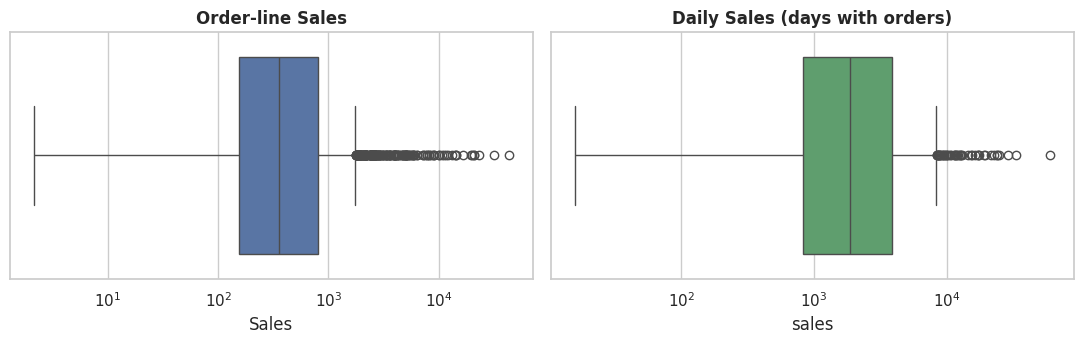

99th percentile of daily sales: 15,991   |   max daily sales: 60,133   |   days above q99: 14


,sales,weekday
date,,
2013-12-29,"60,133.43",Sunday
2012-12-24,"33,479.95",Monday
2012-09-11,"29,134.85",Tuesday
2013-12-16,"24,532.43",Monday
2014-07-24,"23,973.49",Thursday
2014-09-29,"23,799.16",Monday
2012-09-05,"22,685.04",Wednesday
2014-06-16,"21,685.55",Monday


In [11]:
# 2.6 Outliers ---------------------------------------------------------------------------------------------------
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
sns.boxplot(x=raw.Sales, ax=ax[0], color="#4C72B0"); ax[0].set_title("Order-line Sales"); ax[0].set_xscale("log")
sns.boxplot(x=daily[daily > 0], ax=ax[1], color="#55A868"); ax[1].set_title("Daily Sales (days with orders)"); ax[1].set_xscale("log")
plt.tight_layout(); savefig("01_outliers_boxplots"); plt.show()
q99 = daily.quantile(.99)
print(f"99th percentile of daily sales: {q99:,.0f}   |   max daily sales: {daily.max():,.0f}   |   days above q99: {(daily>q99).sum()}")
daily.nlargest(8).to_frame("sales").assign(weekday=lambda d: d.index.day_name())

**Decision on outliers.** A handful of days (e.g. 2013-12-29 with ~60k, while a typical busy day is ~2–4k) are real big orders,
not errors, so they are **kept in the data**. But a model trained with the squared-error loss can be dragged around by the 14 days above the 99th percentile.
Therefore, **only during training**, the daily target is *winsorised* (capped) at the 99th percentile of the training window.
Models are always *evaluated on the real, uncapped sales*. A later experiment (Section 12) checks that this choice does not hurt.

**2.7 Unnecessary columns.** For a forecast of *total daily sales* we only need the date and the sales value.
Customer contact details (`ContactName`, `Fax`, `Phone`, `PostalCode`), employee details (`EmployeeName`, `Extension`, `HireDate`,
`YearSalary`, `Office`, `Title`, `ReportsTo`), geography (`Latitude`, `Longitude`) and IDs are not used as model inputs
(they are personal/descriptive and unknown for future days). Product, category and country are kept **for EDA only**.

**2.8 Leakage detection.** `Quantity`, `Discount`, `COS`, `GP`, `Freight` and the number of orders are *consequences of the same
day's sales* – and `Sales = COS + GP`. They are unknown for a future date, so using them as inputs would make the model
look perfect in the notebook and fail in production. **They are excluded from the features.**
Only information available *before* the day (calendar, and past sales for lag features) is allowed.

## 3. Exploratory Data Analysis (EDA)

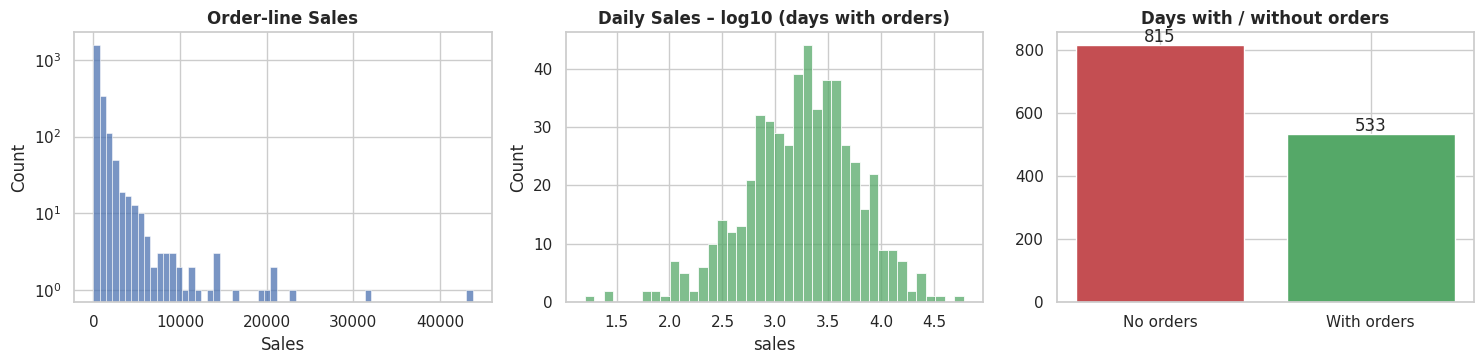

In [12]:
# 3.1 Target distribution --------------------------------------------------------------------------------------
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
sns.histplot(raw.Sales, bins=60, ax=ax[0], color="#4C72B0"); ax[0].set_title("Order-line Sales"); ax[0].set_yscale("log")
sns.histplot(np.log10(daily[daily > 0]), bins=40, ax=ax[1], color="#55A868"); ax[1].set_title("Daily Sales – log10 (days with orders)")
ax[2].bar(["No orders", "With orders"], [(daily == 0).sum(), (daily > 0).sum()], color=["#C44E52", "#55A868"])
ax[2].set_title("Days with / without orders")
for i, v in enumerate([(daily == 0).sum(), (daily > 0).sum()]): ax[2].text(i, v + 10, str(v), ha="center")
plt.tight_layout(); savefig("02_target_distribution"); plt.show()

**Observation.** Sales are **heavily right-skewed** (many small lines, a few very large ones) and the daily series is
**zero-inflated** (≈60 % of days are 0). On the log scale the non-zero days look roughly bell-shaped.
Consequence: error metrics such as MAPE (divide by actual) are impossible (division by zero), and a model that predicts
the *average* day is already a strong benchmark – so we will always compare models against simple baselines.

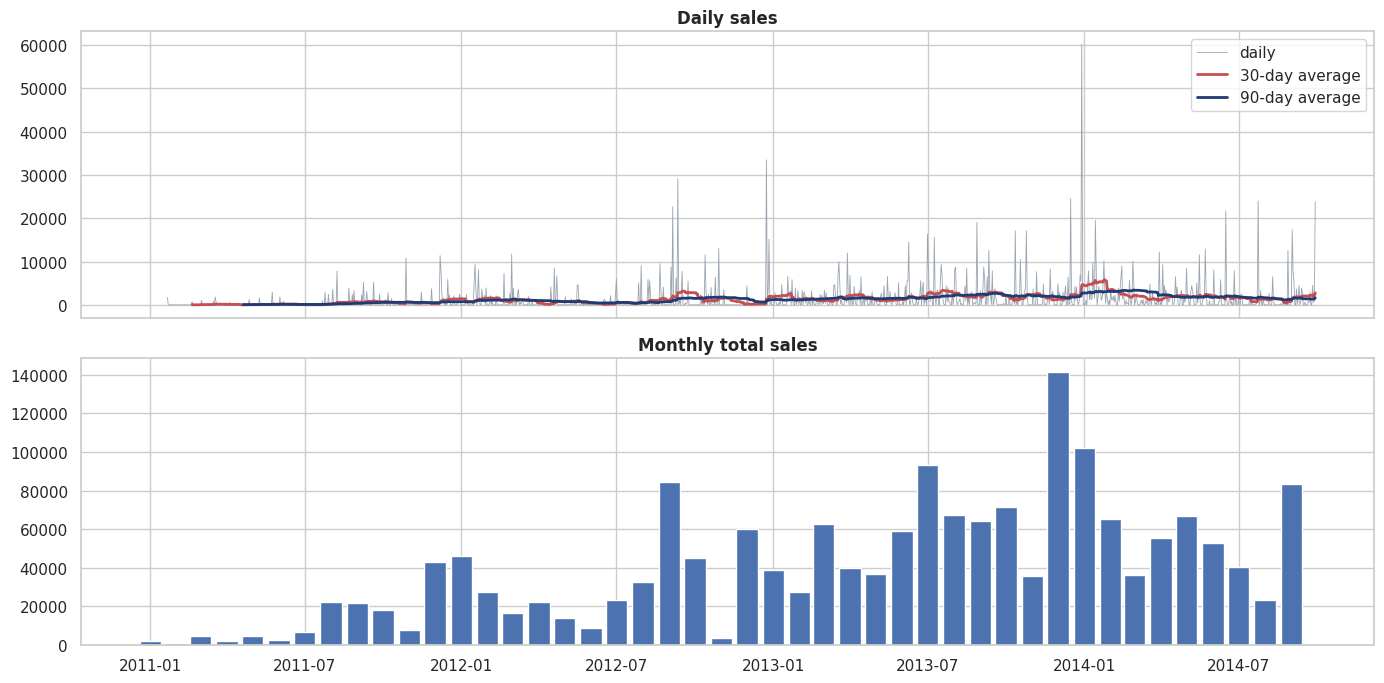

,total sales
date,
2011,"134,382.86"
2012,"384,327.03"
2013,"738,726.98"
2014,"525,710.84"


In [13]:
# 3.2 Sales over time -----------------------------------------------------------------------------------------------
fig, ax = plt.subplots(2, 1, figsize=(14, 7), sharex=True)
ax[0].plot(daily.index, daily.values, lw=.6, color="#9aa5b1", label="daily")
ax[0].plot(daily.rolling(30).mean(), color="#C44E52", lw=2, label="30-day average")
ax[0].plot(daily.rolling(90).mean(), color="#1f3b73", lw=2, label="90-day average"); ax[0].legend(); ax[0].set_title("Daily sales")
monthly = daily.resample("MS").sum()
ax[1].bar(monthly.index, monthly.values, width=25, color="#4C72B0"); ax[1].set_title("Monthly total sales")
plt.tight_layout(); savefig("03_sales_over_time"); plt.show()
yearly = daily.groupby(daily.index.year).sum()
display(yearly.to_frame("total sales"))

**Observation.** (1) **Strong growth** from 2011 (business ramp-up) to 2013–2014 – the series is *not stationary*, it has a trend.
(2) Sales arrive in **bursts**: weeks with many orders, followed by empty weeks. (3) Some months stand out (see seasonality below).
2011 and 2014 are *incomplete years* (history starts on 21-Jan-2011 and ends on 29-Sep-2014).

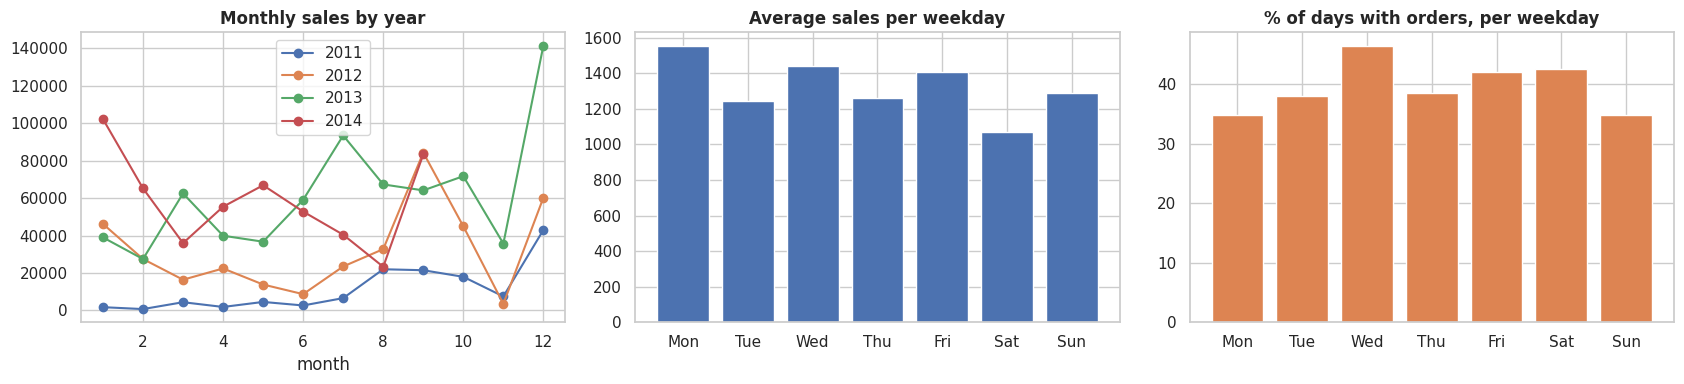

Strongest months (avg of 2012 & 2013): {12: 100908.0, 9: 74238.0, 7: 58487.0}
Weakest months (avg of 2012 & 2013)  : {11: 19606.0, 5: 25280.0, 2: 27462.0}
Weekday spread: best avg = 1,552, worst avg = 1,072


In [14]:
# 3.3 Seasonality: month and weekday ---------------------------------------------------------------------------------
tmp = daily.to_frame("sales")
tmp["month"] = tmp.index.month; tmp["dow"] = tmp.index.dayofweek; tmp["year"] = tmp.index.year
pivot = tmp.pivot_table(index="month", columns="year", values="sales", aggfunc="sum")
fig, ax = plt.subplots(1, 3, figsize=(17, 4))
for y in pivot.columns: ax[0].plot(pivot.index, pivot[y], marker="o", label=str(y))
ax[0].set_title("Monthly sales by year"); ax[0].set_xlabel("month"); ax[0].legend()
dow = tmp.groupby("dow").sales.agg(["mean", lambda s: (s > 0).mean()]); dow.columns = ["avg_sales", "share_days_with_orders"]
ax[1].bar(["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"], dow.avg_sales, color="#4C72B0"); ax[1].set_title("Average sales per weekday")
ax[2].bar(["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"], dow.share_days_with_orders * 100, color="#DD8452")
ax[2].set_title("% of days with orders, per weekday")
plt.tight_layout(); savefig("04_seasonality"); plt.show()
full_years = pivot[[2012, 2013]].mean(axis=1)
print("Strongest months (avg of 2012 & 2013):", full_years.nlargest(3).round(0).to_dict())
print("Weakest months (avg of 2012 & 2013)  :", full_years.nsmallest(3).round(0).to_dict())
print(f"Weekday spread: best avg = {dow.avg_sales.max():,.0f}, worst avg = {dow.avg_sales.min():,.0f}")
RESULTS["strong_months"] = {int(k): float(v) for k, v in full_years.nlargest(3).items()}

**Observation.** There is a clear **yearly pattern**: averaged over the two complete years 2012 and 2013, **December, September and July are the
strongest months and November, May and February the weakest** (printed above). The **weekday effect is weak**: orders occur on all seven days and the differences between
weekdays are small compared with the day-to-day noise. So month-of-year/trend features matter more than day-of-week features.

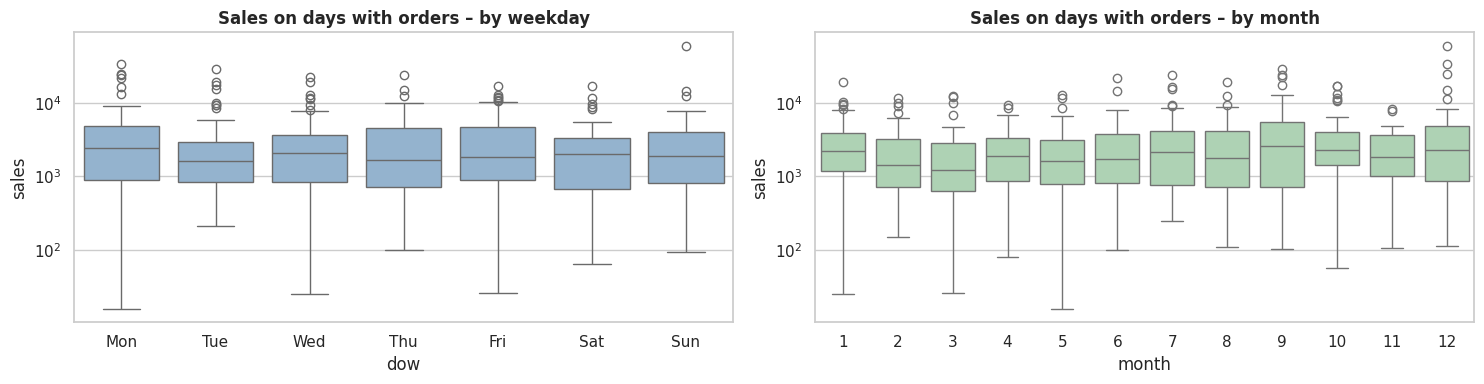

In [15]:
# 3.4 Box plots: spread by weekday & month ---------------------------------------------------------------------------
fig, ax = plt.subplots(1, 2, figsize=(15, 4))
nz = tmp[tmp.sales > 0]
sns.boxplot(data=nz, x="dow", y="sales", ax=ax[0], color="#8ab4d8"); ax[0].set_yscale("log"); ax[0].set_title("Sales on days with orders – by weekday")
ax[0].set_xticklabels(["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"])
sns.boxplot(data=nz, x="month", y="sales", ax=ax[1], color="#a8d8b0"); ax[1].set_yscale("log"); ax[1].set_title("Sales on days with orders – by month")
plt.tight_layout(); savefig("05_boxplots_calendar"); plt.show()

**Observation.** The medians are very similar across weekdays and months (log scale!), and every group contains high outliers.
Differences between months come mostly from **how many days have orders** and a few huge days, not from a much higher "normal" day.

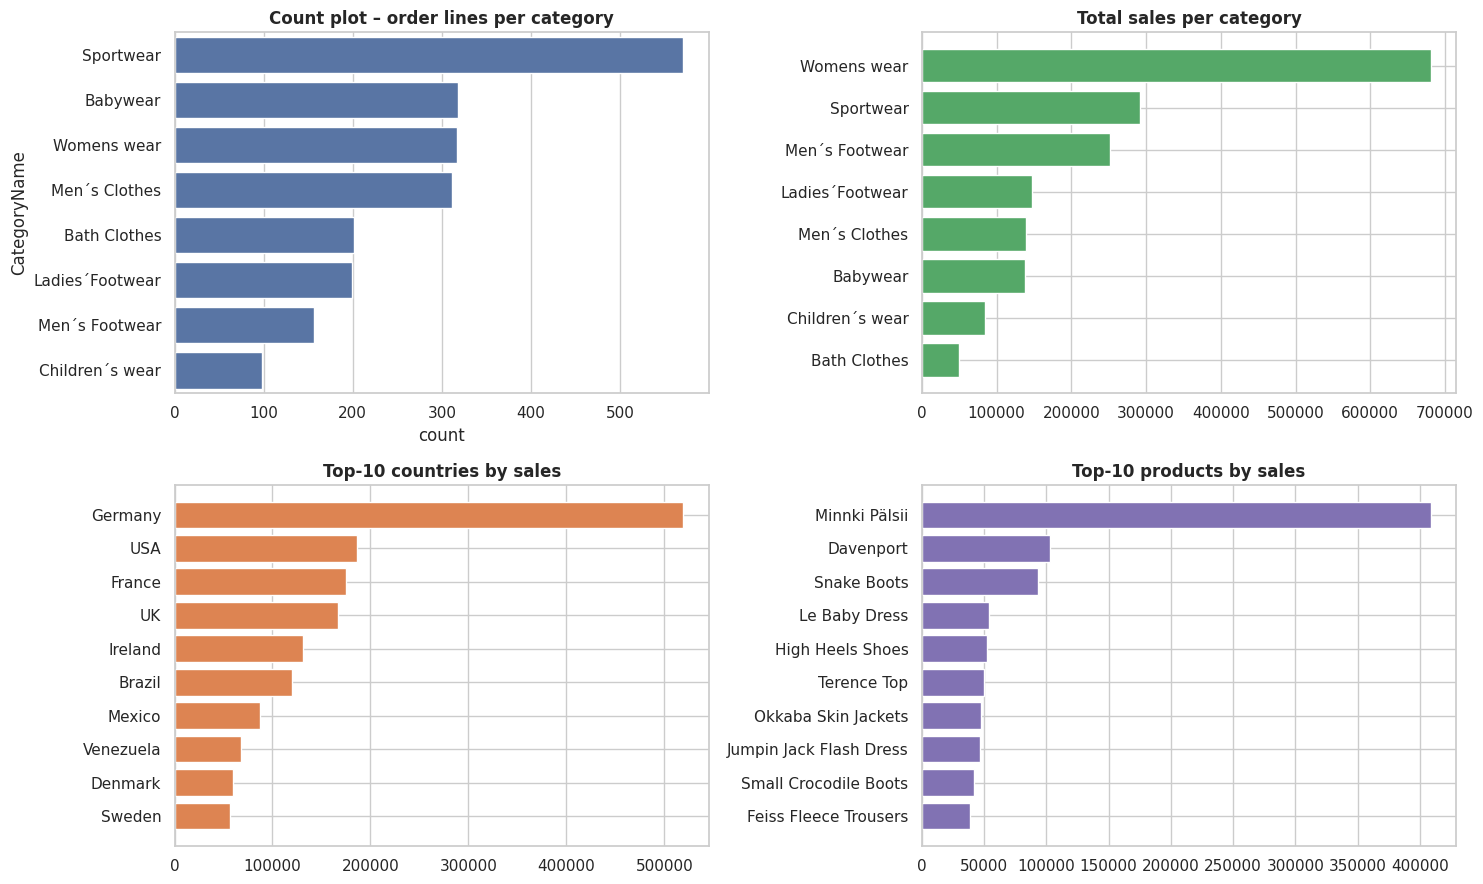

Top-3 countries = 49% of all sales | top-10 products = 52% of all sales


In [16]:
# 3.5 Categorical analysis (count plots + sales by category/country/product) --------------------------------------------
fig, ax = plt.subplots(2, 2, figsize=(15, 9))
order = raw.CategoryName.value_counts().index
sns.countplot(data=raw, y="CategoryName", order=order, ax=ax[0, 0], color="#4C72B0"); ax[0, 0].set_title("Count plot – order lines per category")
cat_sales = raw.groupby("CategoryName").Sales.sum().sort_values()
ax[0, 1].barh(cat_sales.index, cat_sales.values, color="#55A868"); ax[0, 1].set_title("Total sales per category")
top_c = raw.groupby("Country").Sales.sum().nlargest(10).sort_values()
ax[1, 0].barh(top_c.index, top_c.values, color="#DD8452"); ax[1, 0].set_title("Top-10 countries by sales")
top_p = raw.groupby("ProductName").Sales.sum().nlargest(10).sort_values()
ax[1, 1].barh(top_p.index, top_p.values, color="#8172B3"); ax[1, 1].set_title("Top-10 products by sales")
plt.tight_layout(); savefig("06_categorical_analysis"); plt.show()
share_top3_c = raw.groupby("Country").Sales.sum().nlargest(3).sum() / raw.Sales.sum()
print(f"Top-3 countries = {share_top3_c:.0%} of all sales | top-10 products = {top_p.sum()/raw.Sales.sum():.0%} of all sales")

**Observation.** Sales are fairly spread over the 8 product categories, but **a few countries and products generate a large share**
(printed above). For the *total-sales* forecast this is background information; it would matter if we forecast per country/category.

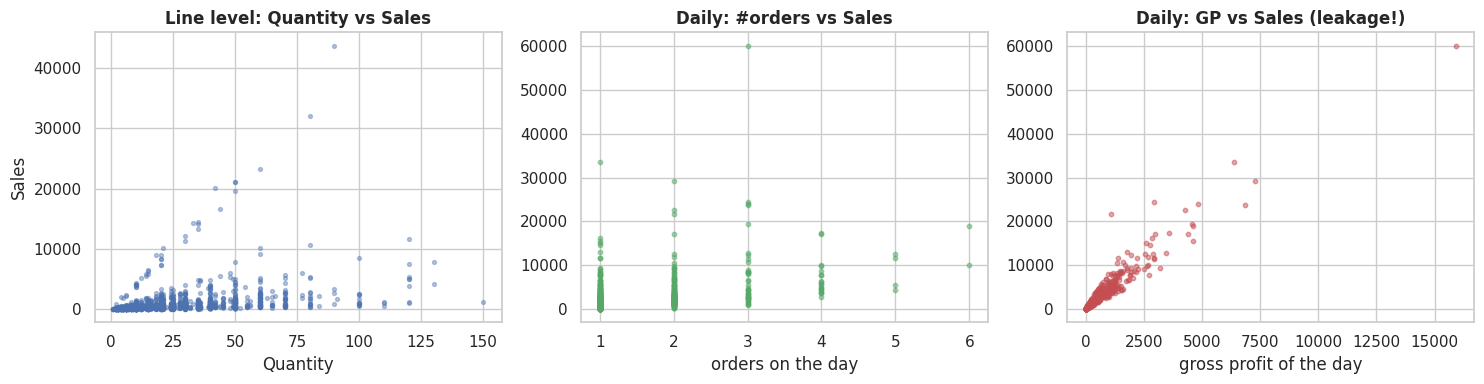

In [17]:
# 3.6 Feature vs target ----------------------------------------------------------------------------------------------
agg = raw.groupby("OrderDate").agg(sales=("Sales", "sum"), quantity=("Quantity", "sum"), discount=("Discount", "sum"),
                                   cos=("COS", "sum"), gp=("GP", "sum"), freight=("Freight", "sum"),
                                   n_orders=("Order", "nunique"), n_lines=("Order", "size"))
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].scatter(raw.Quantity, raw.Sales, s=8, alpha=.4); ax[0].set_xlabel("Quantity"); ax[0].set_ylabel("Sales"); ax[0].set_title("Line level: Quantity vs Sales")
ax[1].scatter(agg.n_orders, agg.sales, s=10, alpha=.5, color="#55A868"); ax[1].set_xlabel("orders on the day"); ax[1].set_title("Daily: #orders vs Sales")
ax[2].scatter(agg.gp, agg.sales, s=10, alpha=.5, color="#C44E52"); ax[2].set_xlabel("gross profit of the day"); ax[2].set_title("Daily: GP vs Sales (leakage!)")
plt.tight_layout(); savefig("07_feature_vs_target"); plt.show()

**Observation.** Same-day quantity, number of orders and profit are strongly related to same-day sales – but that relationship is
*circular* (they are produced by the same orders). The GP-vs-Sales panel is almost a straight line, which is exactly why
those columns are **leakage** and are not allowed as model inputs for a future date.

## 4. Correlation Analysis

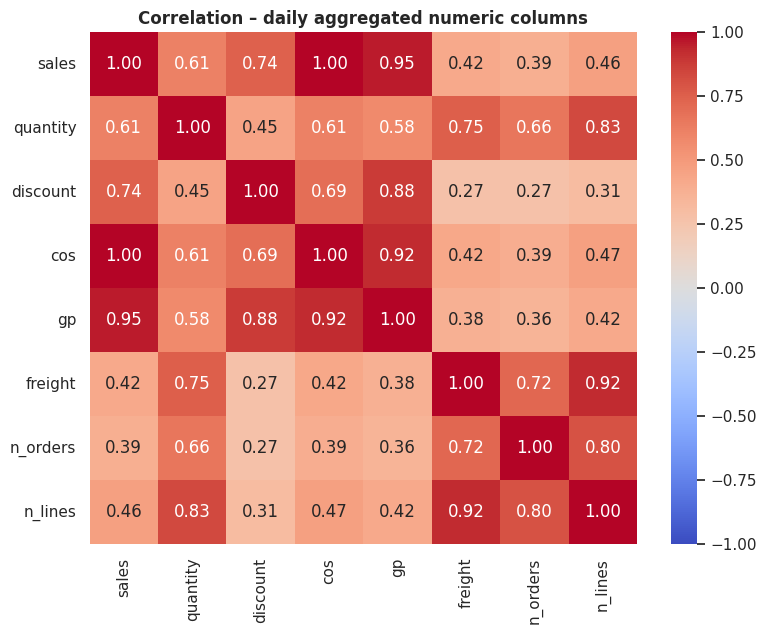

Highly correlated pairs (|r| > 0.90):


r
sales   cos     1.00
        gp      0.95
cos     gp      0.92
freight n_lines 0.92

Weak / no correlation with Sales (|r| < 0.20): {}
Negative correlation with Sales: {}


In [18]:
corr = agg.corr()
plt.figure(figsize=(8, 6.5)); sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1)
plt.title("Correlation – daily aggregated numeric columns"); plt.tight_layout(); savefig("08_corr_raw"); plt.show()
pairs = corr.where(np.triu(np.ones(corr.shape), 1).astype(bool)).stack()
print("Highly correlated pairs (|r| > 0.90):"); display(pairs[pairs.abs() > .9].sort_values(ascending=False).to_frame("r"))
print("Weak / no correlation with Sales (|r| < 0.20):", corr["sales"].drop("sales")[corr["sales"].drop("sales").abs() < .2].round(2).to_dict())
print("Negative correlation with Sales:", corr["sales"].drop("sales")[corr["sales"].drop("sales") < 0].round(2).to_dict())

**Observation.** `cos` (r = 1.00) and `gp` (r = 0.95) are almost perfectly correlated with `sales` because `sales = cos + gp`, and `cos` and `gp`
are correlated with each other (0.92) → **multicollinearity *and* leakage**. `freight` and `n_lines` are also highly correlated (0.92): each shipment
carries freight, so more order lines mean more freight. All other same-day columns (quantity, discount, number of orders…) are also positively
correlated with sales – busy days are busy in *every* column. There are **no negative and no near-zero correlations**, which is itself a sign that these
columns all measure the same thing (the size of the day). Since none of them is known for a future date, they are removed from the model inputs.

## 5. Feature Engineering
Because the future values of `quantity`, `discount`… are unknown, we create **features that are knowable for any future date**:

| Group | Features | Why |
|---|---|---|
| Trend | `t` (days since first sale) | captures long-term growth |
| Calendar | day of week, weekend flag, day of month, week of year, month, quarter, day of year, month-start / month-end / quarter-end, December flag | business cycles (pay-day, month-end ordering, year-end) |
| Cyclical encoding | sin / cos of day-of-year (1st & 2nd harmonic), weekday, month | tells the model that Dec 31 is next to Jan 1 |
| Lag features | sales 1, 7, 14, 28 days ago | recent history |
| Rolling features | mean of last 7 / 14 / 28 / 90 days, std 28, share of days with orders (28), days since last sale | current sales *level* and volatility |

Lag/rolling features are shifted by one day, so **a day never sees its own sales** (no leakage).
Categorical variables need no one-hot encoding because every calendar feature is numeric; scale-sensitive models receive a
`StandardScaler` *inside their pipeline* (fitted only on training data).

We build **two feature sets** and compare them:
* **Set A – calendar only** : can predict all 90 days in one shot ("direct" forecast).
* **Set B – calendar + lags** : needs *recursive* forecasting (predict day 1, feed it back, predict day 2 …), so errors can accumulate.

In [19]:
print(inspect.getsource(fc.lag_features))

def lag_features(series: pd.Series) -> pd.DataFrame:
    """Lag/rolling features for every date in `series`.
    Every value is shifted by one day, so row t only sees days <= t-1 (no leakage)."""
    s = series.astype(float)
    prev = s.shift(1)
    out = pd.DataFrame(index=s.index)
    for k in (1, 7, 14, 28):
        out[f"lag_{k}"] = s.shift(k)
    for w in (7, 14, 28, 90):
        out[f"roll_mean_{w}"] = prev.rolling(w, min_periods=1).mean()
    out["roll_std_28"] = prev.rolling(28, min_periods=2).std()
    out["roll_nonzero_rate_28"] = (prev > 0).astype(float).rolling(28, min_periods=1).mean()
    # days since the last day that had any sales (capped at 90)
    had_sale = (prev > 0).to_numpy()
    pos = np.arange(len(s), dtype=float)
    last_sale_pos = pd.Series(np.where(had_sale, pos, np.nan), index=s.index).ffill().to_numpy()
    out["days_since_last_sale"] = np.clip(np.nan_to_num(pos - last_sale_pos, nan=90.0), 0, 90)
    return out[LAG_FEATURES]



In [20]:
XA = fc.build_frame(daily, use_lags=False); XB = fc.build_frame(daily, use_lags=True)
print("Set A:", XA.shape, "| Set B:", XB.shape, "| NaNs in B:", int(XB.isna().sum().sum()))
XB.tail(3).T.round(2)

Set A: (1348, 20) | Set B: (1320, 31) | NaNs in B: 0


date,2014-09-27,2014-09-28,2014-09-29
t,"1,345.00","1,346.00","1,347.00"
day_of_week,5.00,6.00,0.00
is_weekend,1.00,1.00,0.00
day_of_month,27.00,28.00,29.00
week_of_year,39.00,39.00,40.00
month,9.00,9.00,9.00
quarter,3.00,3.00,3.00
day_of_year,270.00,271.00,272.00
is_month_start,0.00,0.00,0.00
is_month_end,0.00,0.00,0.00


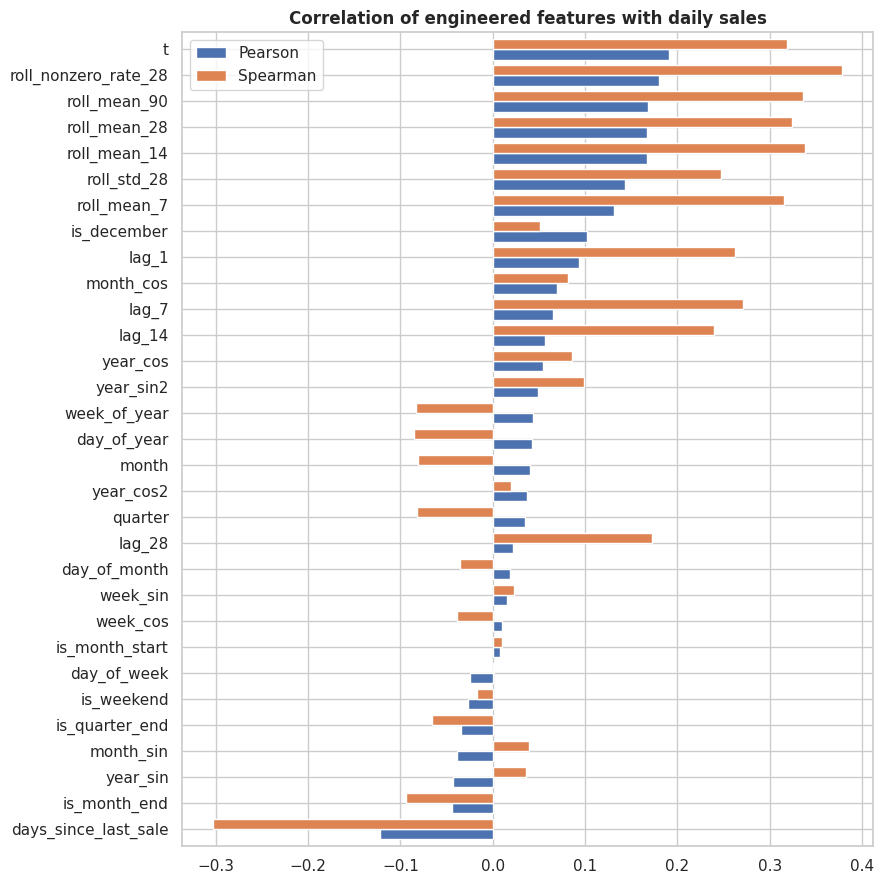

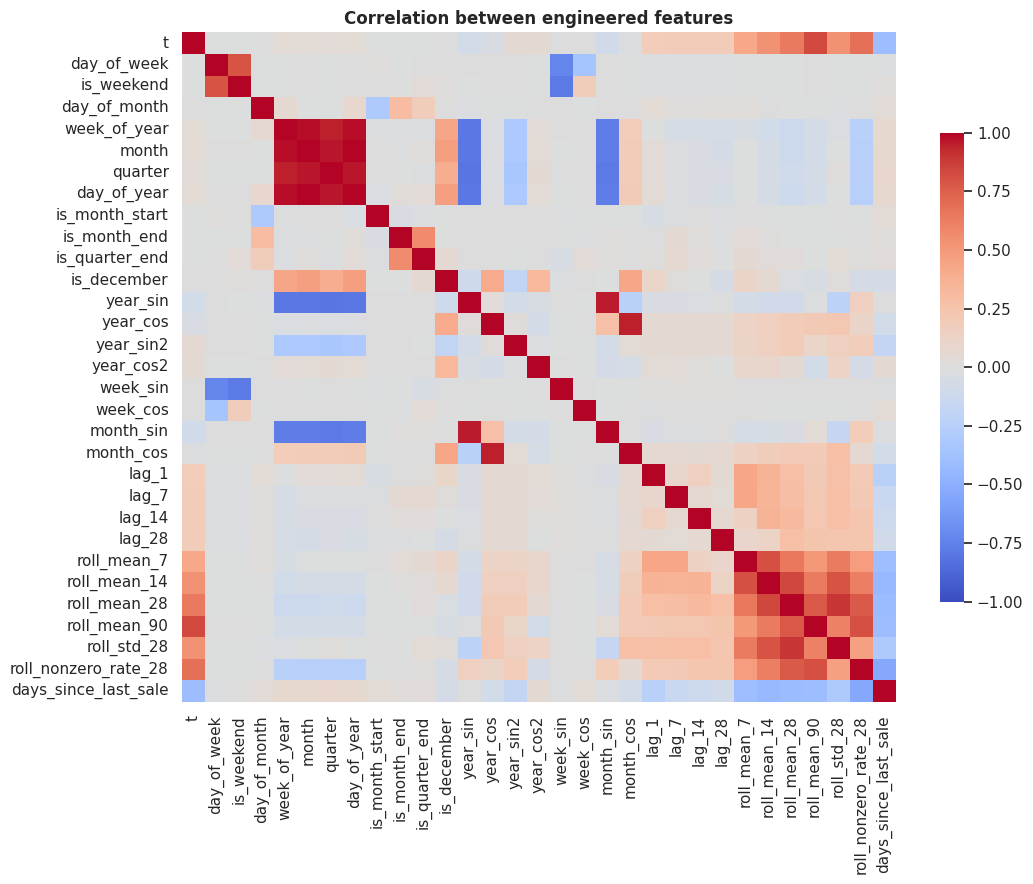

8 feature pairs have |r| > 0.90, e.g.:
month         day_of_year   1.00
week_of_year  day_of_year   0.98
              month         0.98
month         quarter       0.97
quarter       day_of_year   0.96
year_sin      month_sin     0.96
year_cos      month_cos     0.95
week_of_year  quarter       0.95


In [21]:
# correlation of every engineered feature with the target (Pearson + Spearman)
yB = daily.loc[XB.index]
cp = XB.corrwith(yB); cs = XB.corrwith(yB, method="spearman")
cc = pd.DataFrame({"Pearson": cp, "Spearman": cs}).sort_values("Pearson")
cc.plot.barh(figsize=(9, 9), width=.8); plt.title("Correlation of engineered features with daily sales"); plt.tight_layout()
savefig("09_feature_target_corr"); plt.show()
fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(XB.corr(), cmap="coolwarm", center=0, vmin=-1, vmax=1, ax=ax, cbar_kws={"shrink": .7}); ax.set_title("Correlation between engineered features")
plt.tight_layout(); savefig("10_feature_heatmap"); plt.show()
cf = XB.corr().where(np.triu(np.ones((XB.shape[1],) * 2), 1).astype(bool)).stack()
print(f"{(cf.abs() > .9).sum()} feature pairs have |r| > 0.90, e.g.:"); print(cf[cf.abs() > .9].abs().sort_values(ascending=False).head(8).round(2).to_string())

**Observation.** (1) *Every* single feature has a **weak** correlation with the noisy daily target (|r| well below 0.3) – the
strongest ones are the trend `t` and the rolling means (they describe the sales *level*). That is expected for a spiky daily series.
(2) Many features are **highly correlated with each other** (month ↔ quarter ↔ day-of-year ↔ week-of-year ↔ sin/cos: eight pairs with |r| > 0.9) → multicollinearity. It does not hurt tree models; linear models need **regularisation** (Ridge/Lasso…) –
and the feature-selection step below removes redundant columns.

## 6. Feature Selection
We rank the features with three independent methods (**correlation**, **mutual information**, **Random-Forest importance**),
combine them into an *average rank*, and later (Section 10) test whether keeping only the top-*k* features improves the models
("before vs after feature selection"). Selection uses **training data only** (everything before the final 90-day test window)
to avoid leakage.

,abs_corr,mutual_info,rf_importance,avg_rank
t,0.25,0.12,0.18,1.00
roll_mean_14,0.22,0.11,0.09,3.33
roll_mean_28,0.21,0.11,0.06,4.67
roll_std_28,0.18,0.12,0.05,4.67
roll_mean_7,0.18,0.10,0.06,5.00
roll_mean_90,0.23,0.11,0.04,6.00
roll_nonzero_rate_28,0.24,0.07,0.03,7.67
lag_14,0.11,0.05,0.05,9.67
lag_7,0.11,0.05,0.05,10.00
lag_1,0.13,0.03,0.04,11.33


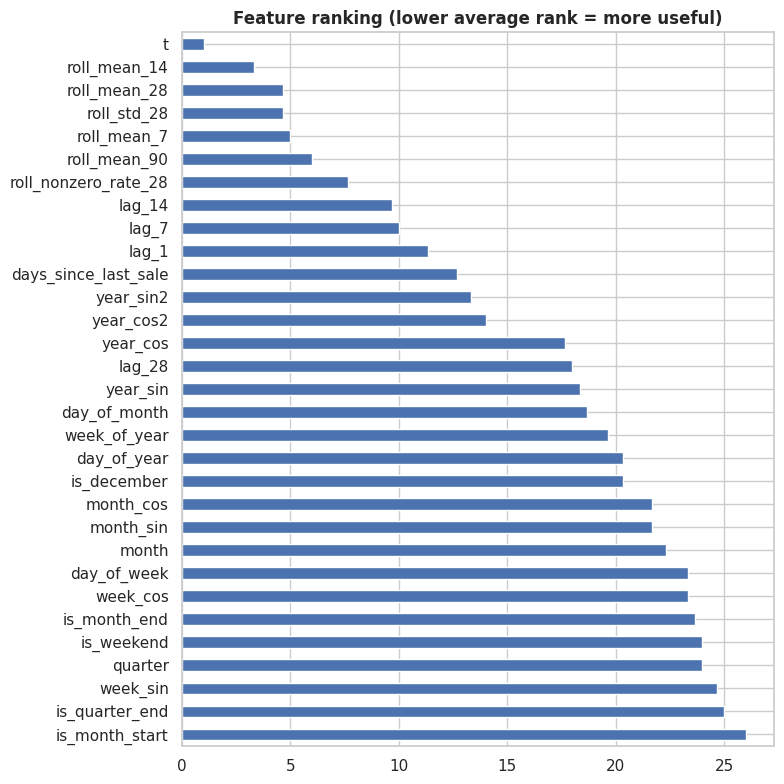

In [22]:
from sklearn.feature_selection import mutual_info_regression
from sklearn.ensemble import RandomForestRegressor
TEST_START = daily.index[-HORIZON]
train_only = daily[daily.index < TEST_START]; train_cap = train_only.clip(upper=train_only.quantile(.99))
XBt = fc.build_frame(train_cap, use_lags=True); yBt = train_cap.loc[XBt.index]
mi = pd.Series(mutual_info_regression(XBt, yBt, random_state=SEED), index=XBt.columns)
rf = RandomForestRegressor(300, min_samples_leaf=10, random_state=SEED, n_jobs=1).fit(XBt, yBt)
rfi = pd.Series(rf.feature_importances_, index=XBt.columns)
cor = XBt.corrwith(yBt).abs()
sel = pd.DataFrame({"abs_corr": cor, "mutual_info": mi, "rf_importance": rfi})
sel["avg_rank"] = sel.rank(ascending=False).mean(axis=1)
sel = sel.sort_values("avg_rank"); RESULTS["feature_ranking"] = sel.round(4).reset_index().rename(columns={"index": "feature"}).to_dict("records")
display(sel.round(4).head(15))
fig, ax = plt.subplots(figsize=(8, 8)); sel["avg_rank"].iloc[::-1].plot.barh(ax=ax, color="#4C72B0")
ax.set_title("Feature ranking (lower average rank = more useful)"); plt.tight_layout(); savefig("11_feature_selection"); plt.show()
RANKED = sel.index.tolist()

## 7. Train / Test Split (time-based, rolling-origin)

A random split would leak the future into training. Instead we **cut the timeline** and repeatedly ask the model the *exact*
question the business will ask: *"given everything up to day D, forecast the next 90 days."*

* **Fold 1 – final TEST window** = the most recent 90 days (2014-07-02 → 2014-09-29). Never used for model choice or tuning.
* **Folds 2, 3, 4 – VALIDATION windows** = the three 90-day windows before it; each is predicted by a model trained only on the data before that window
  (expanding window). Used to compare models and tune hyper-parameters.

One 90-day window of such noisy data would be a lucky-or-unlucky coin toss; averaging three validation windows is much more reliable.

Fold 1 [TEST      ] train: 2011-01-21 → 2014-07-01 (1258 d) | predict: 2014-07-02 → 2014-09-29 (90 d)
Fold 2 [VALIDATION] train: 2011-01-21 → 2014-04-02 (1168 d) | predict: 2014-04-03 → 2014-07-01 (90 d)
Fold 3 [VALIDATION] train: 2011-01-21 → 2014-01-02 (1078 d) | predict: 2014-01-03 → 2014-04-02 (90 d)
Fold 4 [VALIDATION] train: 2011-01-21 → 2013-10-04 (988 d) | predict: 2013-10-05 → 2014-01-02 (90 d)


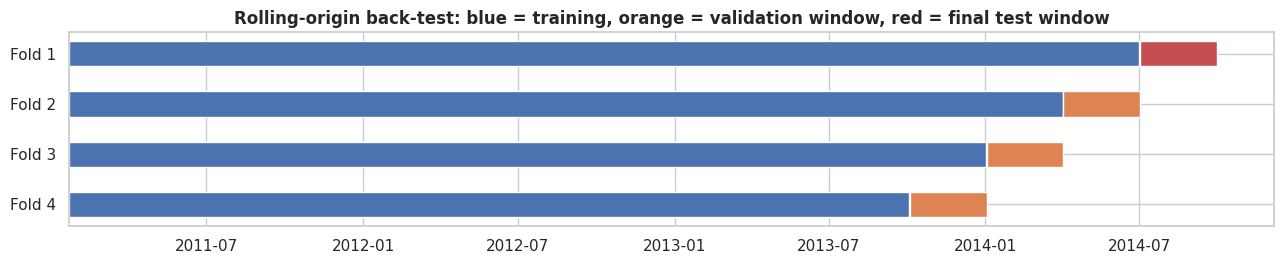

In [23]:
def make_folds(series, H=HORIZON, n_folds=4):
    folds, n = {}, len(series)
    for k in range(1, n_folds + 1):
        end = n - (k - 1) * H; start = end - H
        folds[k] = (series.iloc[:start], series.iloc[start:end])
    return folds
FOLDS = make_folds(daily)
for k, (tr, te) in FOLDS.items():
    role = "TEST      " if k == 1 else "VALIDATION"
    print(f"Fold {k} [{role}] train: {tr.index.min().date()} → {tr.index.max().date()} ({len(tr)} d) | predict: {te.index.min().date()} → {te.index.max().date()} ({len(te)} d)")
VAL_FOLDS, TEST_FOLD = [2, 3, 4], 1

fig, ax = plt.subplots(figsize=(13, 2.8))
for k, (tr, te) in FOLDS.items():
    ax.barh(k, (tr.index.max() - tr.index.min()).days, left=tr.index.min(), color="#4C72B0", height=.5)
    ax.barh(k, HORIZON, left=te.index.min(), color="#C44E52" if k == 1 else "#DD8452", height=.5)
ax.set_yticks(list(FOLDS)); ax.set_yticklabels([f"Fold {k}" for k in FOLDS]); ax.invert_yaxis()
ax.set_title("Rolling-origin back-test: blue = training, orange = validation window, red = final test window")
plt.tight_layout(); savefig("12_split_folds"); plt.show()

## 8. Evaluation metrics for this regression problem
Classification metrics (confusion matrix, accuracy, F1, ROC-AUC) do **not** apply because the target is a continuous amount.
The regression equivalents we use:

| Metric | Meaning | Note |
|---|---|---|
| **RMSE** | typical daily error in sales units, penalises big misses | main daily metric |
| **MAE** | average absolute daily error | reported, but *not* used for ranking: on a series where 60 % of days are 0, the MAE-optimal prediction is ≈ 0, which is useless for revenue planning |
| **R²** | share of daily variance explained (0 = no better than predicting the test-window mean) | will be low – daily noise dominates |
| **WAPE-7d / WAPE-30d** | error on *weekly* / *30-day* totals ÷ actual total | how useful the forecast is for planning |
| **Total-90d error %** | (forecast total − actual total) ÷ actual total over the 90 days | the "quarterly revenue" error; sign shows over/under-forecast |

MAPE is deliberately **not** used (actual = 0 on most days → division by zero).
Models are **ranked** by the average rank on RMSE, WAPE-7d, WAPE-30d and |Total-90d error| (all consistent with predicting the *expected* sales).

In [24]:
def evaluate(y, p):
    p = pd.Series(np.asarray(p, dtype=float), index=y.index); e = y - p
    blk7 = np.arange(len(y)) // 7; m7 = blk7 < len(y) // 7
    blk30 = np.arange(len(y)) // 30; m30 = blk30 < len(y) // 30
    w_y, w_p = y[m7].groupby(blk7[m7]).sum(), p[m7].groupby(blk7[m7]).sum()
    m_y, m_p = y[m30].groupby(blk30[m30]).sum(), p[m30].groupby(blk30[m30]).sum()
    return {"MAE": e.abs().mean(), "RMSE": np.sqrt((e ** 2).mean()),
            "R2": 1 - (e ** 2).sum() / ((y - y.mean()) ** 2).sum(),
            "WAPE_7d": (w_y - w_p).abs().sum() / w_y.sum() * 100,
            "WAPE_30d": (m_y - m_p).abs().sum() / m_y.sum() * 100,
            "Total90_err": (p.sum() - y.sum()) / y.sum() * 100}

In [25]:
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
ORIGIN = daily.index.min()

def fit_and_forecast(est, train, H, use_lags, cols=None, cap_q=0.99):
    """Cap outliers (training only) -> build features -> fit -> forecast H days."""
    cap = train.quantile(cap_q) if cap_q else np.inf
    trc = train.clip(upper=cap) if cap_q else train
    cols = list(cols) if cols is not None else fc.feature_names(use_lags)
    X = fc.build_frame(trc, use_lags, ORIGIN)[cols]; y = trc.loc[X.index]
    m = clone(est); t0 = time.time(); m.fit(X, y); fit_t = time.time() - t0
    t0 = time.time(); p = fc.forecast(m, trc, H, use_lags, cols, ORIGIN, max_value=(cap if cap_q else None)); pred_t = time.time() - t0
    return m, p, fit_t, pred_t

def baseline_forecasts(train, H):
    idx = pd.date_range(train.index[-1] + pd.Timedelta(days=1), periods=H, freq="D")
    ly = train.reindex(idx - pd.Timedelta(days=364)).fillna(0).values
    return {"Baseline: mean of all history": pd.Series(train.mean(), idx),
            "Baseline: mean of last 365 days": pd.Series(train.iloc[-365:].mean(), idx),
            "Baseline: mean of last 90 days": pd.Series(train.iloc[-90:].mean(), idx),
            "Baseline: seasonal naive (same day last year)": pd.Series(ly, idx)}

## 9. Build and compare **all** regression models
Besides Linear and Ridge (required by the assignment) we train **every regression family available** in scikit-learn, plus XGBoost,
LightGBM and CatBoost – 36 models: linear, regularised, robust, generalised-linear, kernel/neighbour, tree, ensemble, boosting, neural network.
Each model is tested on **both feature sets** (A: calendar, B: calendar + lags) → 72 combinations × 4 folds.
(`GammaRegressor` is the only sklearn regressor left out: it requires strictly positive targets and 60 % of our days are 0.)

In [26]:
from sklearn.linear_model import (LinearRegression, Ridge, Lasso, ElasticNet, LassoLars, OrthogonalMatchingPursuit, BayesianRidge,
    ARDRegression, HuberRegressor, TheilSenRegressor, RANSACRegressor, SGDRegressor, PassiveAggressiveRegressor,
    PoissonRegressor, TweedieRegressor, QuantileRegressor)
from sklearn.cross_decomposition import PLSRegression
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR, NuSVR, LinearSVR
from sklearn.kernel_ridge import KernelRidge
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF, WhiteKernel, ConstantKernel as C
from sklearn.tree import DecisionTreeRegressor, ExtraTreeRegressor
from sklearn.ensemble import (RandomForestRegressor, ExtraTreesRegressor, GradientBoostingRegressor, HistGradientBoostingRegressor,
    AdaBoostRegressor, BaggingRegressor, VotingRegressor)
from sklearn.neural_network import MLPRegressor
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
from catboost import CatBoostRegressor

def pipe(est, scale=True):
    return Pipeline([("scale", StandardScaler() if scale else "passthrough"), ("model", est)])

def build_zoo():
    z = {}   # name -> (pipeline, family)
    add = lambda n, e, fam, scale=True: z.__setitem__(n, (pipe(e, scale), fam))
    # --- linear family
    add("Linear Regression", LinearRegression(), "Linear")
    add("Ridge", Ridge(alpha=100), "Linear")
    add("Lasso", Lasso(alpha=20, max_iter=20000), "Linear")
    add("ElasticNet", ElasticNet(alpha=20, l1_ratio=.5, max_iter=20000), "Linear")
    add("Lasso-LARS", LassoLars(alpha=20), "Linear")
    add("Orthogonal Matching Pursuit", OrthogonalMatchingPursuit(n_nonzero_coefs=8), "Linear")
    add("Bayesian Ridge", BayesianRidge(), "Linear")
    add("ARD Regression", ARDRegression(), "Linear")
    add("PLS Regression", PLSRegression(n_components=5), "Linear")
    # --- robust / online / generalised linear
    add("Huber", HuberRegressor(alpha=10, max_iter=500), "Robust / GLM")
    add("Theil-Sen", TheilSenRegressor(random_state=SEED, max_subpopulation=2000), "Robust / GLM")
    add("RANSAC", RANSACRegressor(random_state=SEED), "Robust / GLM")
    add("SGD Regressor", SGDRegressor(alpha=1.0, max_iter=2000, tol=1e-3, random_state=SEED), "Robust / GLM")
    add("Passive-Aggressive", PassiveAggressiveRegressor(C=.01, max_iter=1000, random_state=SEED), "Robust / GLM")
    add("Poisson GLM", PoissonRegressor(alpha=1.0, max_iter=1000), "Robust / GLM")
    add("Tweedie GLM (p=1.5)", TweedieRegressor(power=1.5, alpha=1.0, link="log", max_iter=1000), "Robust / GLM")
    add("Quantile (median)", QuantileRegressor(quantile=.5, alpha=1e-3, solver="highs"), "Robust / GLM")
    # --- kernel / neighbours / GP
    add("KNN", KNeighborsRegressor(n_neighbors=25), "Kernel / Neighbours")
    add("SVR (RBF)", SVR(C=2000, epsilon=50), "Kernel / Neighbours")
    add("NuSVR", NuSVR(C=2000, nu=.5), "Kernel / Neighbours")
    add("Linear SVR", LinearSVR(C=100, epsilon=50, max_iter=20000, random_state=SEED), "Kernel / Neighbours")
    add("Kernel Ridge (RBF)", KernelRidge(alpha=10, kernel="rbf", gamma=.02), "Kernel / Neighbours")
    add("Gaussian Process", GaussianProcessRegressor(kernel=C(1.0) * RBF(5.0) + WhiteKernel(1.0), normalize_y=True, random_state=SEED), "Kernel / Neighbours")
    # --- trees & ensembles
    add("Decision Tree", DecisionTreeRegressor(max_depth=6, min_samples_leaf=20, random_state=SEED), "Tree / Ensemble", False)
    add("Extra Tree (single)", ExtraTreeRegressor(max_depth=6, min_samples_leaf=20, random_state=SEED), "Tree / Ensemble", False)
    add("Random Forest", RandomForestRegressor(300, min_samples_leaf=10, random_state=SEED, n_jobs=1), "Tree / Ensemble", False)
    add("Extra Trees", ExtraTreesRegressor(300, min_samples_leaf=10, random_state=SEED, n_jobs=1), "Tree / Ensemble", False)
    add("Bagging (trees)", BaggingRegressor(DecisionTreeRegressor(min_samples_leaf=10), n_estimators=100, random_state=SEED, n_jobs=1), "Tree / Ensemble", False)
    add("AdaBoost", AdaBoostRegressor(n_estimators=100, learning_rate=.05, random_state=SEED), "Tree / Ensemble", False)
    # --- boosting
    add("Gradient Boosting", GradientBoostingRegressor(n_estimators=150, max_depth=3, learning_rate=.05, subsample=.8, random_state=SEED), "Boosting", False)
    add("HistGradient Boosting", HistGradientBoostingRegressor(max_depth=3, learning_rate=.05, max_iter=150, min_samples_leaf=20, random_state=SEED), "Boosting", False)
    add("XGBoost", XGBRegressor(n_estimators=250, learning_rate=.03, max_depth=3, subsample=.8, colsample_bytree=.8, n_jobs=1, random_state=SEED), "Boosting", False)
    add("LightGBM", LGBMRegressor(n_estimators=200, learning_rate=.03, num_leaves=8, min_child_samples=20, verbose=-1, n_jobs=1, random_state=SEED), "Boosting", False)
    add("CatBoost", CatBoostRegressor(iterations=250, depth=4, learning_rate=.05, verbose=0, thread_count=1, random_seed=SEED), "Boosting", False)
    # --- neural net + voting ensemble
    add("MLP (neural net)", MLPRegressor(hidden_layer_sizes=(32, 16), alpha=1.0, max_iter=400, random_state=SEED), "Neural / Ensemble")
    add("Voting (Ridge+ExtraTrees+GBM+LGBM)", VotingRegressor([("r", pipe(Ridge(alpha=100))), ("e", ExtraTreesRegressor(200, min_samples_leaf=10, random_state=SEED)),
         ("g", GradientBoostingRegressor(n_estimators=150, max_depth=3, learning_rate=.05, subsample=.8, random_state=SEED)),
         ("l", LGBMRegressor(n_estimators=200, learning_rate=.03, num_leaves=8, verbose=-1, n_jobs=1, random_state=SEED))]), "Neural / Ensemble", False)
    return z
ZOO = build_zoo(); print(len(ZOO), "regression models:"); print(", ".join(ZOO))

36 regression models:
Linear Regression, Ridge, Lasso, ElasticNet, Lasso-LARS, Orthogonal Matching Pursuit, Bayesian Ridge, ARD Regression, PLS Regression, Huber, Theil-Sen, RANSAC, SGD Regressor, Passive-Aggressive, Poisson GLM, Tweedie GLM (p=1.5), Quantile (median), KNN, SVR (RBF), NuSVR, Linear SVR, Kernel Ridge (RBF), Gaussian Process, Decision Tree, Extra Tree (single), Random Forest, Extra Trees, Bagging (trees), AdaBoost, Gradient Boosting, HistGradient Boosting, XGBoost, LightGBM, CatBoost, MLP (neural net), Voting (Ridge+ExtraTrees+GBM+LGBM)


In [27]:
# ---- Run the full back-test: every model x 2 feature sets x 4 folds (≈ 3–5 min on one CPU core) --------------------
rows, t_start = [], time.time()
for fold, (tr, te) in FOLDS.items():                                   # baselines (not candidates, only reference points)
    for bn, bp in baseline_forecasts(tr, HORIZON).items():
        rows.append({"model": bn, "family": "Baseline", "feature_set": "-", "fold": fold, **evaluate(te, bp), "fit_s": 0, "predict_s": 0})
fails = {}
for name, (est, fam) in ZOO.items():
    for use_lags, fs in [(False, "A: calendar"), (True, "B: calendar + lags")]:
        for fold, (tr, te) in FOLDS.items():
            try:
                _, p, ft, pt = fit_and_forecast(est, tr, HORIZON, use_lags)
                rows.append({"model": name, "family": fam, "feature_set": fs, "fold": fold, **evaluate(te, p), "fit_s": ft, "predict_s": pt})
            except Exception as ex:
                fails[(name, fs)] = str(ex)[:80]
    print(f"{name:<38} done  ({time.time() - t_start:5.0f}s elapsed)")
BT = pd.DataFrame(rows); BT.to_csv("../docs/backtest_all_folds.csv", index=False)
print("\nFailed combinations:", fails if fails else "none")

Linear Regression                      done  (    3s elapsed)


Ridge                                  done  (    6s elapsed)


Lasso                                  done  (    9s elapsed)


ElasticNet                             done  (   13s elapsed)


Lasso-LARS                             done  (   16s elapsed)


...

XGBoost                                done  (  179s elapsed)


LightGBM                               done  (  182s elapsed)


CatBoost                               done  (  187s elapsed)


MLP (neural net)                       done  (  196s elapsed)


Voting (Ridge+ExtraTrees+GBM+LGBM)     done  (  210s elapsed)

Failed combinations: {('RANSAC', 'A: calendar'): 'RANSAC could not find a valid consensus set. All `max_trials` iterations were sk', ('RANSAC', 'B: calendar + lags'): 'RANSAC could not find a valid consensus set. All `max_trials` iterations were sk'}


In [28]:
# ---- Summarise: validation mean (folds 2-4) and final test (fold 1) --------------------------------------------------------
KEY = ["model", "family", "feature_set"]
val = BT[BT.fold.isin(VAL_FOLDS)].groupby(KEY)[["MAE", "RMSE", "R2", "WAPE_7d", "WAPE_30d", "Total90_err", "fit_s", "predict_s"]].mean()
val["Total90_abs"] = BT[BT.fold.isin(VAL_FOLDS)].assign(a=lambda d: d.Total90_err.abs()).groupby(KEY)["a"].mean()
val["RMSE_std"] = BT[BT.fold.isin(VAL_FOLDS)].groupby(KEY)["RMSE"].std()
test = BT[BT.fold == TEST_FOLD].set_index(KEY)[["MAE", "RMSE", "R2", "WAPE_7d", "WAPE_30d", "Total90_err"]].add_prefix("test_")
LB = val.join(test).reset_index()
rank_cols = ["RMSE", "WAPE_7d", "WAPE_30d", "Total90_abs"]
cand = LB[LB.family != "Baseline"].copy()
cand["score"] = cand[rank_cols].rank().mean(axis=1)              # average rank: lower = better
cand = cand.sort_values("score").reset_index(drop=True); cand.index += 1
base = LB[LB.family == "Baseline"].sort_values("RMSE")
cand.to_csv("../docs/model_leaderboard.csv"); base.to_csv("../docs/baselines.csv", index=False)
show = ["model", "feature_set", "RMSE", "WAPE_7d", "WAPE_30d", "Total90_abs", "score", "test_RMSE", "test_Total90_err"]
print("TOP 15 candidates (validation = mean of folds 2-4; test = fold 1; score = average rank, lower is better)")
display(cand[show].head(15).round(2))
print("Reference baselines (validation mean):"); display(base[["model", "RMSE", "R2", "WAPE_7d", "WAPE_30d", "Total90_err"]].round(2))

TOP 15 candidates (validation = mean of folds 2-4; test = fold 1; score = average rank, lower is better)


,model,feature_set,RMSE,WAPE_7d,WAPE_30d,Total90_abs,score,test_RMSE,test_Total90_err
1,Linear Regression,A: calendar,"4,610.10",44.67,27.85,13.50,2.75,"4,430.03",74.05
2,Orthogonal Matching Pursuit,B: calendar + lags,"4,624.68",45.12,30.28,14.44,5.25,"4,380.27",62.89
3,Lasso,A: calendar,"4,630.62",45.70,30.48,13.46,5.75,"4,367.61",64.66
4,Lasso-LARS,A: calendar,"4,630.63",45.70,30.48,13.46,5.75,"4,367.61",64.66
5,Ridge,A: calendar,"4,631.16",45.22,29.06,14.43,5.75,"4,354.82",61.16
6,ARD Regression,A: calendar,"4,631.49",46.06,30.60,14.15,8.50,"4,370.56",64.72
7,Orthogonal Matching Pursuit,A: calendar,"4,633.92",46.03,30.80,13.75,8.50,"4,371.45",70.06
8,Bayesian Ridge,A: calendar,"4,636.52",45.53,29.47,15.34,8.75,"4,346.64",58.90
9,PLS Regression,A: calendar,"4,634.14",46.26,30.45,14.01,8.75,"4,389.76",70.18
10,Tweedie GLM (p=1.5),B: calendar + lags,"4,654.10",47.85,21.62,9.13,9.50,"4,680.55",113.51


Reference baselines (validation mean):


,model,RMSE,R2,WAPE_7d,WAPE_30d,Total90_err
8,Baseline: mean of last 90 days,"4,642.35",-0.01,50.01,33.37,5.10
7,Baseline: mean of last 365 days,"4,651.50",-0.01,47.23,32.29,-12.56
6,Baseline: mean of all history,"4,769.63",-0.07,54.19,49.69,-49.09
9,Baseline: seasonal naive (same day last year),"5,794.72",-0.68,78.12,55.50,-34.17


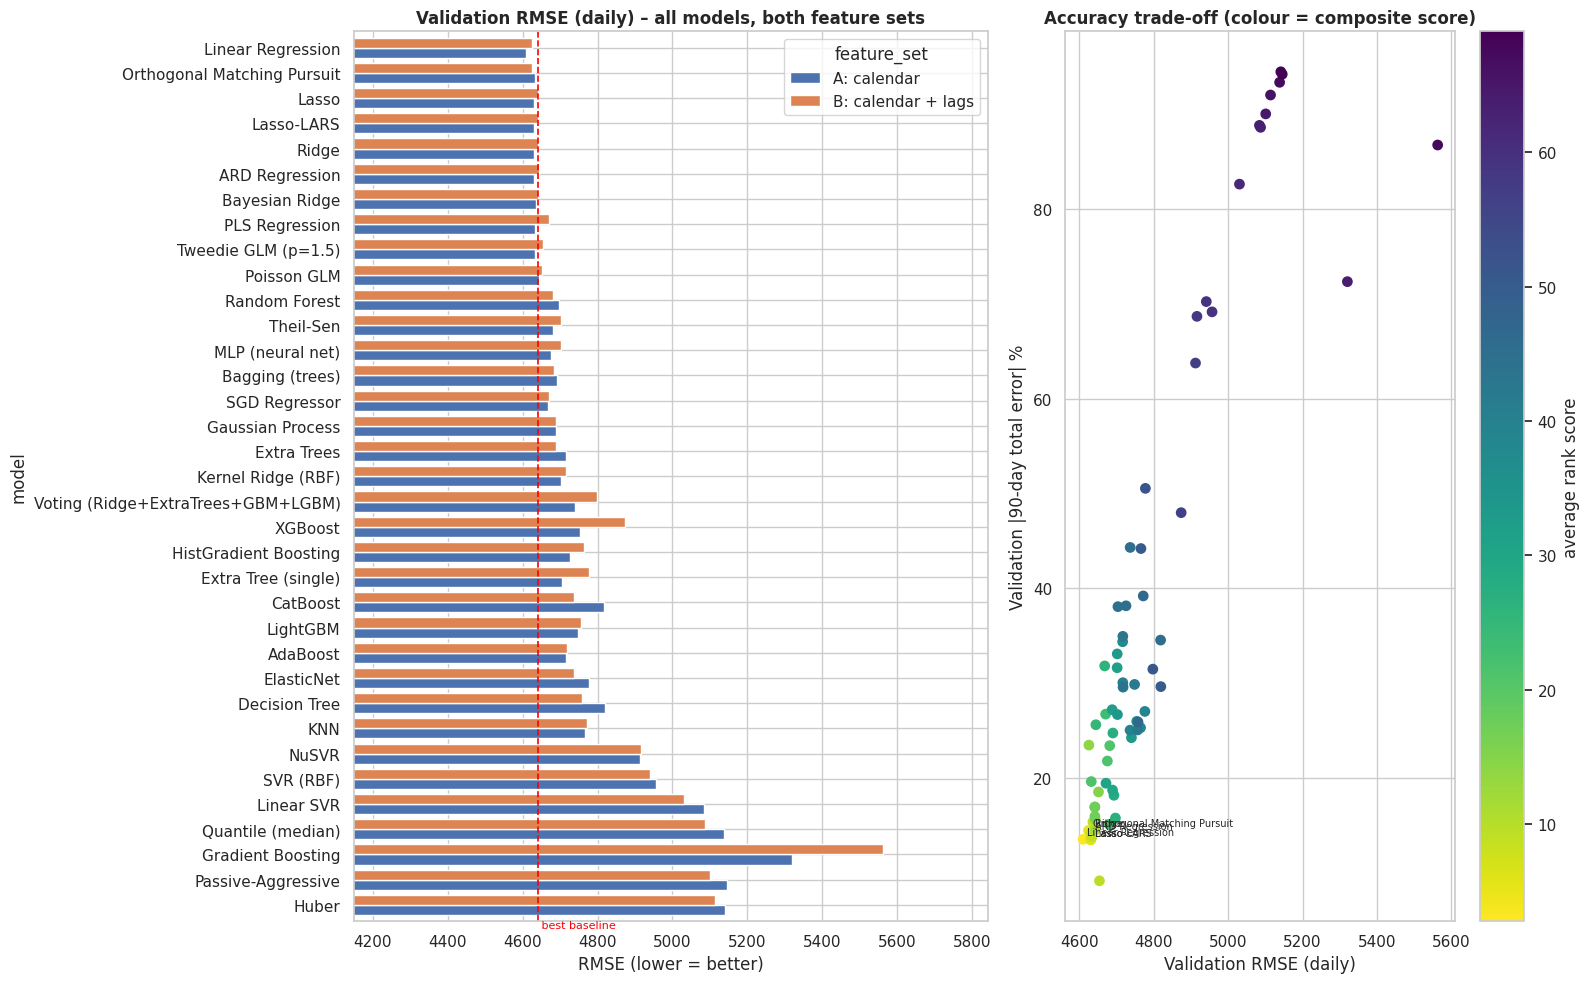

In [29]:
# ---- Visual comparison of all models ----------------------------------------------------------------------------------------
fig, ax = plt.subplots(1, 2, figsize=(16, 10), gridspec_kw={"width_ratios": [1.3, 1]})
order = cand.groupby("model").score.min().sort_values().index[::-1]
pv = cand.pivot_table(index="model", columns="feature_set", values="RMSE").loc[order]
pv.plot.barh(ax=ax[0], width=.8, color=["#4C72B0", "#DD8452"]); ax[0].set_title("Validation RMSE (daily) – all models, both feature sets")
ax[0].axvline(base.RMSE.min(), color="red", ls="--", lw=1.2); ax[0].text(base.RMSE.min(), -0.9, " best baseline", color="red", fontsize=8)
ax[0].set_xlim(left=pv.min().min() * .9); ax[0].set_xlabel("RMSE (lower = better)")
sc = ax[1].scatter(cand.RMSE, cand.Total90_abs, c=cand.score, cmap="viridis_r", s=45)
for _, r in cand.head(6).iterrows(): ax[1].annotate(r.model, (r.RMSE, r.Total90_abs), fontsize=7, xytext=(3, 3), textcoords="offset points")
ax[1].set_xlabel("Validation RMSE (daily)"); ax[1].set_ylabel("Validation |90-day total error| %"); ax[1].set_title("Accuracy trade-off (colour = composite score)")
plt.colorbar(sc, ax=ax[1], label="average rank score"); plt.tight_layout(); savefig("13_model_comparison"); plt.show()

In [30]:
# ---- Feature-set and family summary ------------------------------------------------------------------------------------------
print("Average validation RMSE by feature set (all models):"); display(cand.groupby("feature_set")[["RMSE", "WAPE_7d", "Total90_abs"]].mean().round(2))
print("Best combination per model family:"); display(cand.sort_values("score").groupby("family").head(1)[["family", "model", "feature_set", "RMSE", "WAPE_30d", "Total90_abs", "score"]].round(2))
RESULTS["n_models"] = len(ZOO); RESULTS["n_combos"] = int(len(cand)); RESULTS["best_baseline"] = base.iloc[0][["model", "RMSE", "WAPE_7d", "WAPE_30d", "Total90_err"]].to_dict()

Average validation RMSE by feature set (all models):


,RMSE,WAPE_7d,Total90_abs
feature_set,,,
A: calendar,"4,774.53",57.62,36.65
B: calendar + lags,"4,783.19",58.84,36.01


Best combination per model family:


,family,model,feature_set,RMSE,WAPE_30d,Total90_abs,score
1,Linear,Linear Regression,A: calendar,"4,610.10",27.85,13.50,2.75
10,Robust / GLM,Tweedie GLM (p=1.5),B: calendar + lags,"4,654.10",21.62,9.13,9.50
18,Tree / Ensemble,Random Forest,B: calendar + lags,"4,680.01",35.74,15.09,20.00
21,Neural / Ensemble,MLP (neural net),A: calendar,"4,675.40",36.42,21.77,21.50
27,Kernel / Neighbours,Gaussian Process,A: calendar,"4,690.17",36.84,24.73,27.25
36,Boosting,XGBoost,A: calendar,"4,754.19",36.03,25.96,34.00


**Observation (model comparison).**
1. Daily sales are dominated by random spikes, so *no* model reaches a meaningful daily R² (all are around 0). The best models beat the best simple benchmark
   on daily RMSE by only about 1 % – smaller than the fold-to-fold variation – so the models are compared on **several** metrics and always next to the **baselines**.
2. **Simple, regularised linear models on calendar features rank first.** Flexible models (Random Forest, boosting, neural network, Gaussian process) fit the
   noise in the spikes and rank lower; they would need much more data. The lag/rolling features of Set B did not help on average (see the feature-set table):
   recursive forecasting over 90 days lets small errors feed back into the lag features.
3. `RANSAC` failed on every fold (it needs a consensus set, impossible when 60 % of the target is 0) – it is reported as failed and excluded.
4. The top-ranked combinations that have a tuning grid are carried to feature selection and tuning below.

## 10. Feature selection – before vs after
For the 3 best-ranked (tunable) combinations we compare **all features** with the **top-k features** from Section 6 (k = 8, 12, 16),
using the validation folds only.

In [31]:
from itertools import product
def cv_eval(est, use_lags, cols=None, cap_q=0.99):
    """Mean validation metrics over folds 2-4 for one configuration."""
    res = []
    for k in VAL_FOLDS:
        tr, te = FOLDS[k]; _, p, _, _ = fit_and_forecast(est, tr, HORIZON, use_lags, cols, cap_q); res.append(evaluate(te, p))
    r = pd.DataFrame(res); out = r.mean(); out["Total90_abs"] = r.Total90_err.abs().mean(); return out

GRIDS = {
 "Ridge": {"model__alpha": [.01, .1, 1, 10, 100, 1000, 5000]}, "Lasso": {"model__alpha": [.5, 1, 5, 20, 100, 300]},
 "ElasticNet": {"model__alpha": [5, 20, 100], "model__l1_ratio": [.2, .5, .8]},
 "Bayesian Ridge": {"model__alpha_2": [1e-6, 1e-3], "model__lambda_2": [1e-6, 1e-2, 1]},
 "Huber": {"model__alpha": [1, 10, 100]}, "Poisson GLM": {"model__alpha": [.1, 1, 10, 100]},
 "Tweedie GLM (p=1.5)": {"model__alpha": [.1, 1, 10, 100], "model__power": [1.2, 1.5, 1.8]},
 "KNN": {"model__n_neighbors": [10, 25, 50, 100], "model__weights": ["uniform", "distance"]},
 "SVR (RBF)": {"model__C": [200, 2000, 20000], "model__epsilon": [10, 50, 200]},
 "Kernel Ridge (RBF)": {"model__alpha": [1, 10, 100], "model__gamma": [.005, .02, .05]},
 "Random Forest": {"model__min_samples_leaf": [5, 10, 20, 40], "model__max_features": [.5, 1.0]},
 "Extra Trees": {"model__min_samples_leaf": [5, 10, 20, 40], "model__max_features": [.5, 1.0]},
 "Gradient Boosting": {"model__learning_rate": [.02, .05], "model__n_estimators": [100, 200], "model__max_depth": [2, 3]},
 "HistGradient Boosting": {"model__learning_rate": [.03, .08], "model__max_depth": [2, 3, 4], "model__min_samples_leaf": [20, 50]},
 "XGBoost": {"model__max_depth": [2, 3, 4], "model__learning_rate": [.02, .05], "model__n_estimators": [150, 300]},
 "LightGBM": {"model__num_leaves": [4, 8, 16], "model__learning_rate": [.02, .05], "model__min_child_samples": [20, 50]},
 "CatBoost": {"model__depth": [3, 4, 6], "model__learning_rate": [.03, .08]},
 "Decision Tree": {"model__max_depth": [3, 5, 8], "model__min_samples_leaf": [10, 20, 40]},
 "AdaBoost": {"model__learning_rate": [.01, .05, .2], "model__n_estimators": [50, 100]},
 "MLP (neural net)": {"model__alpha": [.1, 1, 10], "model__hidden_layer_sizes": [(16,), (32, 16)]},
}
tunable = cand[cand.model.isin(GRIDS)].drop_duplicates("model").head(3)
print("Candidates carried to feature selection + tuning:"); display(tunable[["model", "feature_set", "RMSE", "WAPE_30d", "Total90_abs", "score"]].round(2))

Candidates carried to feature selection + tuning:


,model,feature_set,RMSE,WAPE_30d,Total90_abs,score
3,Lasso,A: calendar,"4,630.62",30.48,13.46,5.75
5,Ridge,A: calendar,"4,631.16",29.06,14.43,5.75
8,Bayesian Ridge,A: calendar,"4,636.52",29.47,15.34,8.75


In [32]:
fs_rows, CHOSEN = [], {}
for _, r in tunable.iterrows():
    use_lags = r.feature_set.startswith("B"); allcols = fc.feature_names(use_lags); ranked = [c for c in RANKED if c in allcols]
    best_name, best_val = "all features", None
    options = {"all features": allcols, **{f"top {k}": ranked[:k] for k in (8, 12, 16) if k < len(allcols)}}
    res = {}
    for nm, cols in options.items():
        s = cv_eval(ZOO[r.model][0], use_lags, cols); res[nm] = s
        fs_rows.append({"model": r.model, "feature_set": r.feature_set, "features": nm, "n_features": len(cols), "RMSE": s.RMSE,
                        "WAPE_7d": s.WAPE_7d, "WAPE_30d": s.WAPE_30d, "Total90_abs": s.Total90_abs})
    tbl = pd.DataFrame(res).T[["RMSE", "WAPE_7d", "WAPE_30d", "Total90_abs"]]
    pick = tbl.rank().mean(axis=1).idxmin()                           # same average-rank rule
    CHOSEN[r.model] = {"use_lags": use_lags, "cols": options[pick], "choice": pick, "feature_set": r.feature_set}
FS = pd.DataFrame(fs_rows); display(FS.round(2))
print({k: v["choice"] for k, v in CHOSEN.items()})
FS.to_csv("../docs/feature_selection_comparison.csv", index=False)

,model,feature_set,features,n_features,RMSE,WAPE_7d,WAPE_30d,Total90_abs
0,Lasso,A: calendar,all features,20,"4,630.62",45.70,30.48,13.46
1,Lasso,A: calendar,top 8,8,"4,644.69",47.50,32.59,14.24
2,Lasso,A: calendar,top 12,12,"4,631.26",46.12,30.60,13.48
3,Lasso,A: calendar,top 16,16,"4,629.19",45.50,30.60,13.47
4,Ridge,A: calendar,all features,20,"4,631.16",45.22,29.06,14.43
5,Ridge,A: calendar,top 8,8,"4,650.18",47.59,32.18,14.17
6,Ridge,A: calendar,top 12,12,"4,634.37",45.77,29.41,14.35
7,Ridge,A: calendar,top 16,16,"4,631.62",44.97,29.33,14.35
8,Bayesian Ridge,A: calendar,all features,20,"4,636.52",45.53,29.47,15.34
9,Bayesian Ridge,A: calendar,top 8,8,"4,650.93",47.76,32.45,13.94


{'Lasso': 'all features', 'Ridge': 'top 16', 'Bayesian Ridge': 'top 16'}


**Observation.** The table compares *before* (all features) and *after* (top-k). If a smaller subset has equal or better validation
error, it is preferred: fewer inputs = simpler, faster and less prone to over-fitting. The chosen subset per model is printed above and is used for tuning.

## 11. Hyper-parameter tuning
Grid search with **time-aware validation** (folds 2-4, never the test fold). `GridSearchCV` with random folds would leak the future,
so the grid is evaluated with our own rolling-origin loop. For every grid point the same 4-metric average-rank rule is used.

In [33]:
TUNED, tune_log = {}, []
for name, cfg in CHOSEN.items():
    grid = GRIDS[name]; keys = list(grid); best = None; rows_g = []
    for vals in product(*grid.values()):
        params = dict(zip(keys, vals)); est = clone(ZOO[name][0]).set_params(**params)
        s = cv_eval(est, cfg["use_lags"], cfg["cols"]); rows_g.append({**params, **s[["RMSE", "WAPE_7d", "WAPE_30d", "Total90_abs"]].to_dict()})
    G = pd.DataFrame(rows_g); G["score"] = G[["RMSE", "WAPE_7d", "WAPE_30d", "Total90_abs"]].rank().mean(axis=1)
    b = G.sort_values("score").iloc[0]; bp = {k: (b[k] if not isinstance(b[k], np.generic) else b[k].item()) for k in keys}
    for k in keys:                                       # restore tuples / ints lost by DataFrame conversion
        if isinstance(grid[k][0], tuple): bp[k] = [g for g in grid[k] if str(g) == str(b[k])][0]
        elif isinstance(grid[k][0], int) and not isinstance(grid[k][0], bool): bp[k] = int(bp[k])
    tuned = clone(ZOO[name][0]).set_params(**bp)
    before = cv_eval(ZOO[name][0], cfg["use_lags"], cfg["cols"]); after = cv_eval(tuned, cfg["use_lags"], cfg["cols"])
    TUNED[name] = {"est": tuned, "params": bp, **cfg}
    tune_log.append({"model": name, "feature_set": cfg["feature_set"], "features": cfg["choice"], "best_params": {k.replace("model__", ""): v for k, v in bp.items()},
                     "grid_points": len(G), "RMSE_before": before.RMSE, "RMSE_after": after.RMSE, "WAPE30_before": before.WAPE_30d, "WAPE30_after": after.WAPE_30d,
                     "Total90abs_before": before.Total90_abs, "Total90abs_after": after.Total90_abs})
    print(f"{name:<22} best params: {tune_log[-1]['best_params']}")
TL = pd.DataFrame(tune_log); TL.to_csv("../docs/tuning_results.csv", index=False)
display(TL.drop(columns=["best_params"]).round(2))

# Top-3 combinations that have NO hyper-parameters (e.g. plain Linear Regression) cannot be tuned, but they must not be dropped:
# they join the final comparison exactly as they are.
for _, r in cand.head(3).iterrows():
    if r.model not in GRIDS and r.model not in TUNED:
        ub = r.feature_set.startswith("B")
        TUNED[r.model] = {"est": ZOO[r.model][0], "params": {}, "use_lags": ub, "cols": fc.feature_names(ub), "choice": "all features", "feature_set": r.feature_set}
        tune_log.append({"model": r.model, "feature_set": r.feature_set, "features": "all features", "best_params": {}, "grid_points": 0})
        print(f"{r.model} ({r.feature_set}) has no hyper-parameters – carried to the final comparison un-tuned.")

Lasso                  best params: {'alpha': 0.5}


Ridge                  best params: {'alpha': 0.1}


Bayesian Ridge         best params: {'alpha_2': 1e-06, 'lambda_2': 1.0}


,model,feature_set,features,grid_points,RMSE_before,RMSE_after,WAPE30_before,WAPE30_after,Total90abs_before,Total90abs_after
0,Lasso,A: calendar,all features,6,"4,630.62","4,606.97",30.48,27.37,13.46,14.47
1,Ridge,A: calendar,top 16,7,"4,631.62","4,607.73",29.33,28.02,14.35,14.58
2,Bayesian Ridge,A: calendar,top 16,6,"4,633.82","4,633.82",29.47,29.47,14.88,14.88


Linear Regression (A: calendar) has no hyper-parameters – carried to the final comparison un-tuned.
Orthogonal Matching Pursuit (B: calendar + lags) has no hyper-parameters – carried to the final comparison un-tuned.


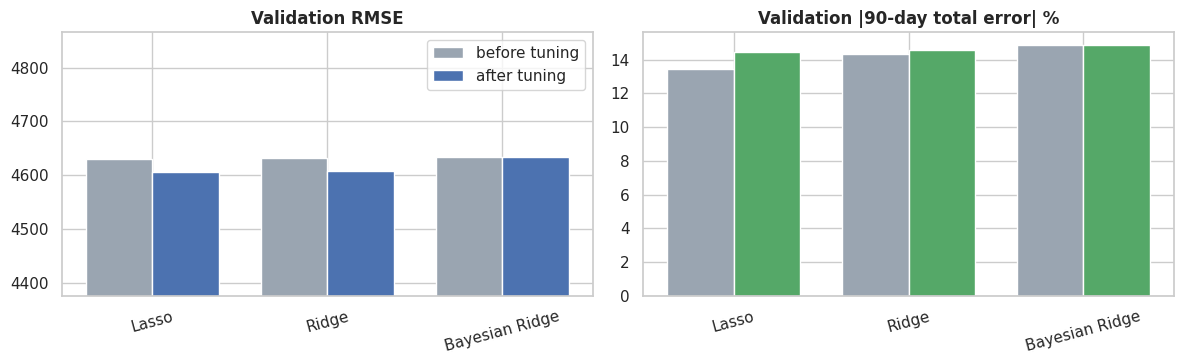

In [34]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8)); x = np.arange(len(TL)); w = .38
ax[0].bar(x - w / 2, TL.RMSE_before, w, label="before tuning", color="#9aa5b1"); ax[0].bar(x + w / 2, TL.RMSE_after, w, label="after tuning", color="#4C72B0")
ax[0].set_xticks(x); ax[0].set_xticklabels(TL.model, rotation=15); ax[0].set_title("Validation RMSE"); ax[0].legend(); ax[0].set_ylim(TL[["RMSE_before", "RMSE_after"]].min().min() * .95)
ax[1].bar(x - w / 2, TL.Total90abs_before, w, color="#9aa5b1"); ax[1].bar(x + w / 2, TL.Total90abs_after, w, color="#55A868")
ax[1].set_xticks(x); ax[1].set_xticklabels(TL.model, rotation=15); ax[1].set_title("Validation |90-day total error| %")
plt.tight_layout(); savefig("14_tuning_before_after"); plt.show()

## 12. Final model selection
The model with the lowest error is **not automatically** the deployment choice. Candidates are compared on accuracy (validation), stability
(variation across folds), the untouched **test window**, inference time and complexity. The rule used in code: *lowest average rank over
RMSE / WAPE-7d / WAPE-30d / |Total-90d error| on the validation folds; ties are resolved in favour of the faster, simpler model.* The test window is only
used to **confirm** the choice, never to make it.

In [35]:
def complexity(est):
    m = est.named_steps["model"] if hasattr(est, "named_steps") else est
    if hasattr(m, "estimators_") and not isinstance(m, VotingRegressor): return f"{len(m.estimators_)} trees"
    if hasattr(m, "n_estimators"): return f"{m.n_estimators} boosting rounds"
    if hasattr(m, "coef_"): return f"linear, {int(np.size(m.coef_))} coefficients"
    if hasattr(m, "tree_"): return f"1 tree, depth {m.get_depth()}"
    return type(m).__name__

fin_rows = []
for name, t in TUNED.items():
    v_runs, t_runs = [], None
    for k in VAL_FOLDS:
        tr, te = FOLDS[k]; _, p, ft, pt = fit_and_forecast(t["est"], tr, HORIZON, t["use_lags"], t["cols"]); v_runs.append({**evaluate(te, p), "fit_s": ft, "predict_s": pt})
    tr, te = FOLDS[TEST_FOLD]; m, p, ft, pt = fit_and_forecast(t["est"], tr, HORIZON, t["use_lags"], t["cols"]); te_m = evaluate(te, p)
    V = pd.DataFrame(v_runs)
    fin_rows.append({"model": name, "feature_set": t["feature_set"], "n_features": len(t["cols"]), "RMSE": V.RMSE.mean(), "RMSE_std": V.RMSE.std(), "WAPE_7d": V.WAPE_7d.mean(),
                     "WAPE_30d": V.WAPE_30d.mean(), "Total90_abs": V.Total90_err.abs().mean(), "test_RMSE": te_m["RMSE"], "test_R2": te_m["R2"], "test_WAPE_30d": te_m["WAPE_30d"],
                     "test_Total90_err": te_m["Total90_err"], "forecast_s": V.predict_s.mean(), "complexity": complexity(m)})
FIN = pd.DataFrame(fin_rows); FIN["score"] = FIN[["RMSE", "WAPE_7d", "WAPE_30d", "Total90_abs"]].rank().mean(axis=1)
FIN = FIN.sort_values(["score", "forecast_s"]).reset_index(drop=True); FIN.to_csv("../docs/final_candidates.csv", index=False)
display(FIN.round(2))
WINNER = FIN.iloc[0].model; W = TUNED[WINNER]
bb = RESULTS["best_baseline"]
print(f"\nSELECTED MODEL: {WINNER}  | feature set {W['feature_set']} | {len(W['cols'])} features | params {tune_log[[t['model'] for t in tune_log].index(WINNER)]['best_params']}")
print(f"Validation RMSE {FIN.iloc[0].RMSE:,.0f} vs best baseline ({bb['model']}) {bb['RMSE']:,.0f}")

,model,feature_set,n_features,RMSE,RMSE_std,WAPE_7d,WAPE_30d,Total90_abs,test_RMSE,test_R2,test_WAPE_30d,test_Total90_err,forecast_s,complexity,score
0,Lasso,A: calendar,20,"4,606.97","2,275.62",43.96,27.37,14.47,"4,411.70",-0.08,71.42,71.42,0.01,"linear, 20 coefficients",1.75
1,Linear Regression,A: calendar,20,"4,610.10","2,253.62",44.67,27.85,13.50,"4,430.03",-0.09,74.05,74.05,0.01,"linear, 20 coefficients",2.25
2,Ridge,A: calendar,16,"4,607.73","2,267.05",43.66,28.02,14.58,"4,400.22",-0.07,71.11,71.11,0.01,"linear, 16 coefficients",2.50
3,Orthogonal Matching Pursuit,B: calendar + lags,31,"4,624.68","2,284.64",45.12,30.28,14.44,"4,380.27",-0.06,69.41,62.89,0.63,"linear, 31 coefficients",4.00
4,Bayesian Ridge,A: calendar,16,"4,633.82","2,294.80",45.09,29.47,14.88,"4,347.29",-0.05,65.46,61.05,0.01,"linear, 16 coefficients",4.50



SELECTED MODEL: Lasso  | feature set A: calendar | 20 features | params {'alpha': 0.5}
Validation RMSE 4,607 vs best baseline (Baseline: mean of last 90 days) 4,642


In [36]:
# Does capping outliers in the TRAINING target help? (evaluated on raw sales)
ab = []
for q, lab in [(None, "no capping"), (0.995, "cap at 99.5th pct"), (0.99, "cap at 99th pct (used)"), (0.95, "cap at 95th pct")]:
    s = cv_eval(W["est"], W["use_lags"], W["cols"], cap_q=q); ab.append({"training target": lab, "RMSE": s.RMSE, "WAPE_30d": s.WAPE_30d, "Total90_abs": s.Total90_abs})
AB = pd.DataFrame(ab); display(AB.round(2)); AB.to_csv("../docs/outlier_capping_ablation.csv", index=False)

,training target,RMSE,WAPE_30d,Total90_abs
0,no capping,"4,612.26",28.76,16.97
1,cap at 99.5th pct,"4,603.28",27.43,15.02
2,cap at 99th pct (used),"4,606.97",27.37,14.47
3,cap at 95th pct,"4,640.48",32.79,24.71


### Test-window evaluation of the selected model
Now (and only now) we look at the untouched **most recent 90 days**: forecast made with data up to 2014-07-01, compared with what really happened.

,MAE,RMSE,R2,WAPE_7d,WAPE_30d,Total90_err
Selected model,"3,016.70","4,411.70",-0.08,143.63,71.42,71.42
BL: mean of all history,"2,112.96","4,264.35",-0.01,89.85,41.37,-19.52
BL: mean of last 365 days,"2,707.00","4,306.33",-0.03,119.00,61.85,41.91
BL: mean of last 90 days,"2,493.71","4,266.19",-0.01,106.72,54.88,21.00
BL: seasonal naive (same day last year),"3,111.87","5,575.29",-0.72,130.18,63.91,37.49


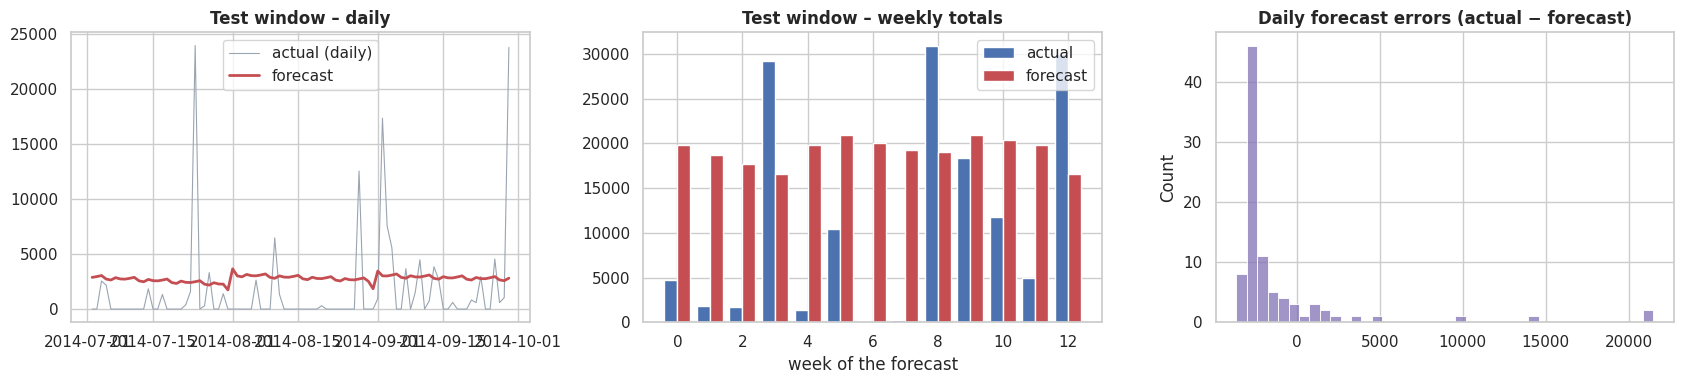

Actual 90-day total: 145,571 | Forecast: 249,535 | error +71.4%


In [37]:
tr, te = FOLDS[TEST_FOLD]; m_t, p_t, _, _ = fit_and_forecast(W["est"], tr, HORIZON, W["use_lags"], W["cols"])
TEST_M = evaluate(te, p_t); RESULTS["test_metrics"] = {k: float(v) for k, v in TEST_M.items()}
bl = baseline_forecasts(tr, HORIZON); bl_m = {n: evaluate(te, f) for n, f in bl.items()}
display(pd.DataFrame({"Selected model": TEST_M, **{n.replace("Baseline: ", "BL: "): v for n, v in bl_m.items()}}).T.round(2))

fig, ax = plt.subplots(1, 3, figsize=(17, 4))
ax[0].plot(te.index, te.values, color="#9aa5b1", lw=.8, label="actual (daily)"); ax[0].plot(p_t.index, p_t.values, color="#C44E52", lw=2, label="forecast")
ax[0].set_title("Test window – daily"); ax[0].legend()
wk_a = te.groupby(np.arange(len(te)) // 7).sum(); wk_f = p_t.groupby(np.arange(len(te)) // 7).sum()
ax[1].bar(wk_a.index - .2, wk_a.values, .4, label="actual", color="#4C72B0"); ax[1].bar(wk_f.index + .2, wk_f.values, .4, label="forecast", color="#C44E52")
ax[1].set_title("Test window – weekly totals"); ax[1].set_xlabel("week of the forecast"); ax[1].legend()
res = te - p_t; sns.histplot(res, bins=40, ax=ax[2], color="#8172B3"); ax[2].set_title("Daily forecast errors (actual − forecast)")
plt.tight_layout(); savefig("15_test_window"); plt.show()
print(f"Actual 90-day total: {te.sum():,.0f} | Forecast: {p_t.sum():,.0f} | error {TEST_M['Total90_err']:+.1f}%")

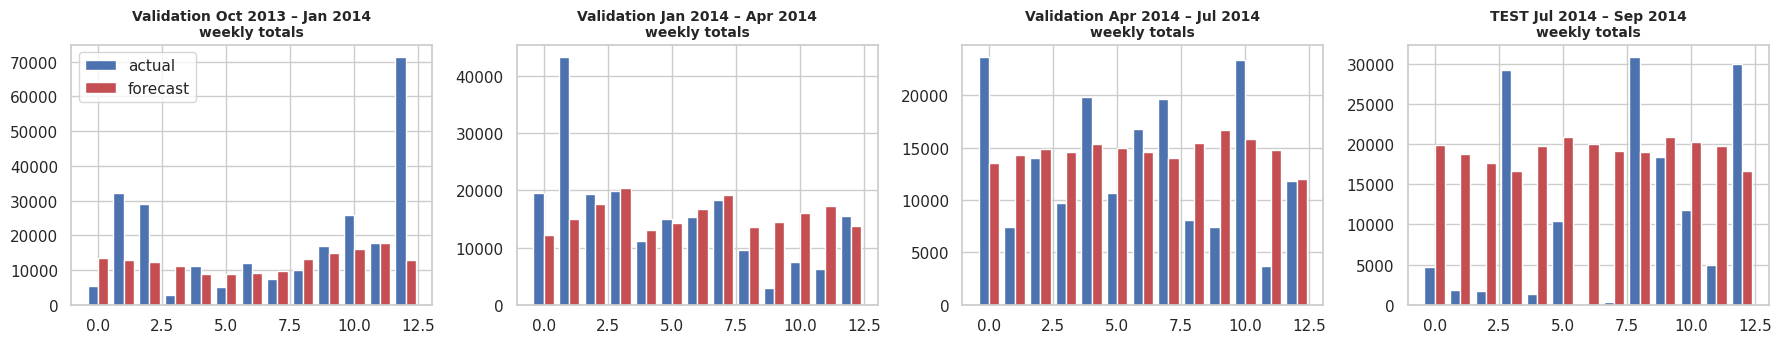

In [38]:
# Back-test of the selected model on all four windows (shows consistency across time)
fig, ax = plt.subplots(1, 4, figsize=(18, 3.6), sharey=False); RES_ALL = []
for i, k in enumerate([4, 3, 2, 1]):
    tr_k, te_k = FOLDS[k]; _, p_k, _, _ = fit_and_forecast(W["est"], tr_k, HORIZON, W["use_lags"], W["cols"]); RES_ALL.append((te_k, p_k))
    a = te_k.groupby(np.arange(len(te_k)) // 7).sum(); f = p_k.groupby(np.arange(len(te_k)) // 7).sum()
    ax[i].bar(a.index - .2, a.values, .4, color="#4C72B0", label="actual"); ax[i].bar(f.index + .2, f.values, .4, color="#C44E52", label="forecast")
    ax[i].set_title(f"{'TEST' if k == 1 else 'Validation'} {te_k.index.min():%b %Y} – {te_k.index.max():%b %Y}\nweekly totals", fontsize=10)
ax[0].legend(); plt.tight_layout(); savefig("16_backtest_all_windows"); plt.show()

In [39]:
# Honest check: 90-day TOTAL error (forecast vs actual, %) of the selected model and the baselines in each of the four windows
rows = []
for (te_k, p_k), k in zip(RES_ALL, [4, 3, 2, 1]):
    bl_k = baseline_forecasts(FOLDS[k][0], HORIZON)
    r = {"window": f"{te_k.index.min():%d %b %Y} – {te_k.index.max():%d %b %Y}", "role": "TEST" if k == 1 else "validation", "actual_total": te_k.sum(),
         "Selected model": (p_k.sum() / te_k.sum() - 1) * 100}
    for n, f in bl_k.items(): r[n.replace("Baseline: ", "BL: ")] = (f.sum() / te_k.sum() - 1) * 100
    rows.append(r)
WIN = pd.DataFrame(rows).set_index("window"); display(WIN.round(1))
val_abs = WIN[WIN.role == "validation"].drop(columns=["role", "actual_total"]).abs().mean(); best_bl = val_abs.drop("Selected model").idxmin()
print(f"Average |90-day total error| on the 3 validation windows: selected model {val_abs['Selected model']:.1f}%  vs best baseline ({best_bl}) {val_abs[best_bl]:.1f}%")
print(f"Latest (TEST) window: selected model {WIN.loc[WIN.role == 'TEST', 'Selected model'].iloc[0]:+.1f}%  vs {best_bl} {WIN.loc[WIN.role == 'TEST', best_bl].iloc[0]:+.1f}%")
y13 = daily.loc["2013-07-02":"2013-09-29"].sum(); y14 = daily.loc["2014-07-02":"2014-09-29"].sum()
print(f"Context: sales in the test window were {y14 / y13 - 1:+.0%} versus the same weeks of 2013, while Jan–Sep 2014 overall was "
      f"{daily.loc['2014-01-01':'2014-09-29'].sum() / daily.loc['2013-01-01':'2013-09-29'].sum() - 1:+.0%} versus Jan–Sep 2013.")

,role,actual_total,Selected model,BL: mean of all history,BL: mean of last 365 days,BL: mean of last 90 days,BL: seasonal naive (same day last year)
window,,,,,,,
05 Oct 2013 – 02 Jan 2014,validation,"247,099.40",-34.80,-62.70,-40.10,-21.70,-54.90
03 Jan 2014 – 02 Apr 2014,validation,"203,765.70",0.10,-48.50,-10.60,21.30,-33.50
03 Apr 2014 – 01 Jul 2014,validation,"176,139.20",8.50,-36.10,13.00,15.70,-14.10
02 Jul 2014 – 29 Sep 2014,TEST,"145,571.40",71.40,-19.50,41.90,21.00,37.50


Average |90-day total error| on the 3 validation windows: selected model 14.5%  vs best baseline (BL: mean of last 90 days) 19.5%
Latest (TEST) window: selected model +71.4%  vs BL: mean of last 90 days +21.0%
Context: sales in the test window were -30% versus the same weeks of 2013, while Jan–Sep 2014 overall was +7% versus Jan–Sep 2013.


**Honest verdict on the test window.** The model was chosen on the validation windows, and the test window is where it is checked. The table above shows
that the **selected model is competitive with the best benchmark on the validation windows, but over-forecast the most recent window by a large margin** –
that window was an unusually weak quarter (sales fell sharply versus the same weeks of the previous year, printed above), while the model extrapolates the
long-term growth trend. A model that extrapolates growth is exposed to exactly this risk; the benchmark that only repeats the recent average is not, but it
cannot see the yearly seasonal pattern and under-forecast strong quarters (first window). **We therefore treat the forecast as a baseline planning scenario
and always show its wide uncertainty band**, and the model should be re-trained whenever new data arrives.

**Observation.** Weekly totals are very erratic (a week can be 0 or 35k) – the forecast follows the *typical level and seasonal shape*,
not individual bursts. This is the honest limit of what the data can support; the planning-grade information is in the
**30-day and 90-day totals** and in the uncertainty band computed next.

## 13. Final training and the 90-day forecast
The selected configuration is re-trained on **all available history** and used to forecast the next 90 days
(the day after the last date in the data, 2014-09-30, to 2014-12-28).
Uncertainty bands are built from the **real out-of-sample errors** of the four back-test windows (5 % – 95 % quantiles of the errors).

In [40]:
FINAL_MODEL, FC, fit_t, pred_t = fit_and_forecast(W["est"], daily, HORIZON, W["use_lags"], W["cols"])
CAP = float(daily.quantile(.99))
err_d = pd.concat([a - b for a, b in RES_ALL])
def block_err(n):
    out = []
    for a, b in RES_ALL:
        d = (a - b); out += [d.iloc[i:i + n].sum() for i in range(0, len(d) - n + 1, n)]
    return np.array(out)
INTERVALS = {"daily": {"q05": float(err_d.quantile(.05)), "q95": float(err_d.quantile(.95))},
             "weekly": {"q05": float(np.quantile(block_err(7), .05)), "q95": float(np.quantile(block_err(7), .95))},
             "30day": {"q05": float(np.quantile(block_err(30), .05)), "q95": float(np.quantile(block_err(30), .95))},
             "90day": {"q05": float(np.quantile(block_err(90), .05)), "q95": float(np.quantile(block_err(90), .95))}}
print("Error quantiles (actual − forecast) from back-tests:"); display(pd.DataFrame(INTERVALS).T.round(0))
fc_df = FC.to_frame("forecast"); fc_df["lower"] = (fc_df.forecast + INTERVALS["daily"]["q05"]).clip(lower=0); fc_df["upper"] = fc_df.forecast + INTERVALS["daily"]["q95"]
print(f"Forecast period: {FC.index.min().date()} → {FC.index.max().date()} | total = {FC.sum():,.0f} | avg per day = {FC.mean():,.0f} | inference time = {pred_t * 1000:.0f} ms")
tot = FC.sum(); print(f"90-day total: {tot:,.0f}  (5-95% range {max(tot + INTERVALS['90day']['q05'], 0):,.0f} – {tot + INTERVALS['90day']['q95']:,.0f})")
fc_df.head(7).round(0)

Error quantiles (actual − forecast) from back-tests:


,q05,q95
daily,"-2,907.00","7,012.00"
weekly,"-17,880.00","15,385.00"
30day,"-49,413.00","48,753.00"
90day,"-90,623.00","73,049.00"


Forecast period: 2014-09-30 → 2014-12-28 | total = 213,215 | avg per day = 2,369 | inference time = 6 ms
90-day total: 213,215  (5-95% range 122,592 – 286,264)


,forecast,lower,upper
2014-09-30,"1,406.00",0.00,"8,418.00"
2014-10-01,"2,689.00",0.00,"9,701.00"
2014-10-02,"2,422.00",0.00,"9,434.00"
2014-10-03,"2,491.00",0.00,"9,503.00"
2014-10-04,"2,199.00",0.00,"9,211.00"
2014-10-05,"2,170.00",0.00,"9,182.00"
2014-10-06,"2,427.00",0.00,"9,439.00"


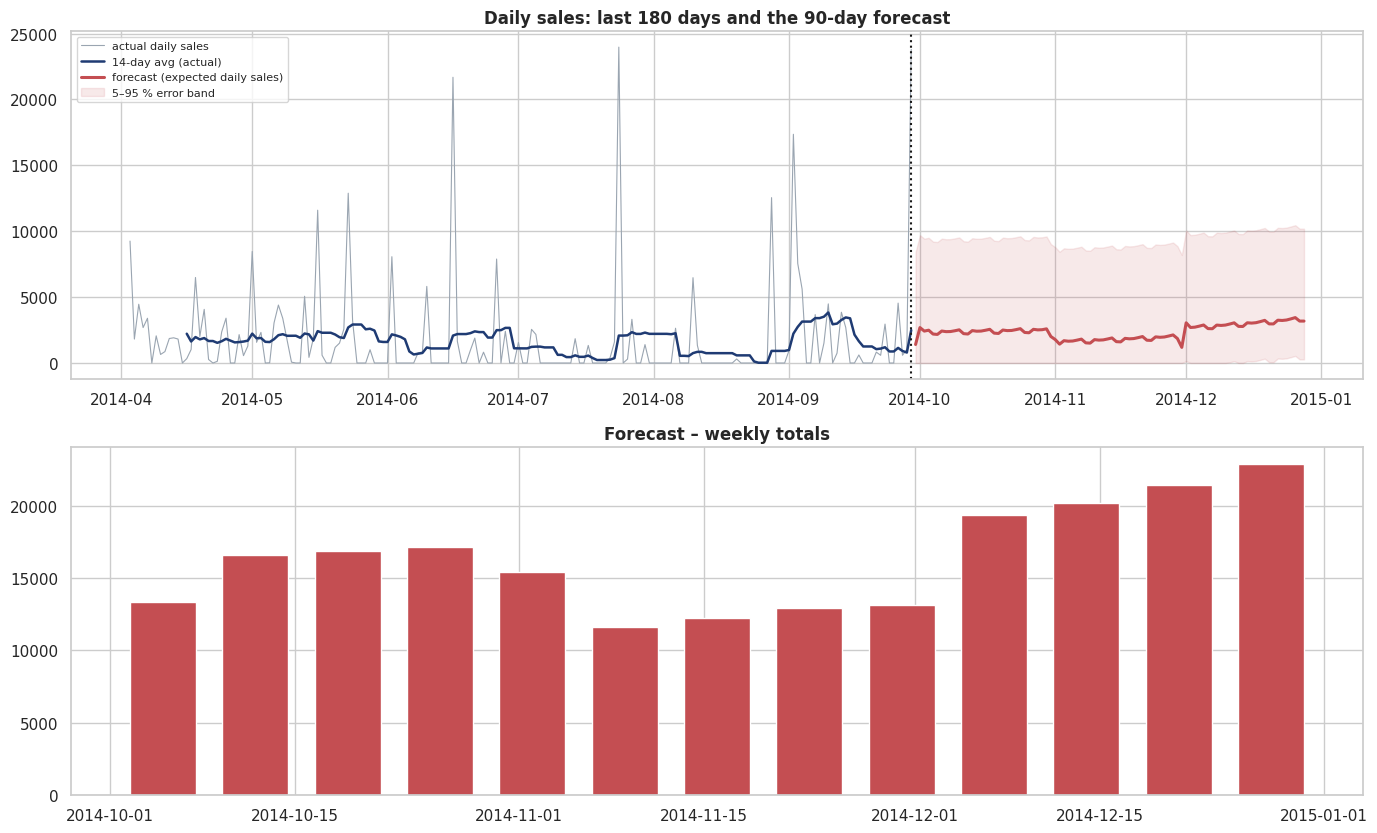

Forecast by calendar month: {Period('2014-09', 'M'): 1406.0, Period('2014-10', 'M'): 74799.0, Period('2014-11', 'M'): 53110.0, Period('2014-12', 'M'): 83899.0}
Same 90 days one year earlier (actual): 243,463  → forecast is -12% vs last year
Reasonableness check: year-to-date 2014 is +7% vs 2013, the forecast for the next 90 days is -12% vs the same days of 2013 (a deliberately cautious level compared with the year-to-date growth).


In [41]:
fig, ax = plt.subplots(2, 1, figsize=(14, 8.5))
hist = daily.iloc[-180:]
ax[0].plot(hist.index, hist.values, color="#9aa5b1", lw=.8, label="actual daily sales"); ax[0].plot(hist.rolling(14).mean(), color="#1f3b73", lw=1.8, label="14-day avg (actual)")
ax[0].plot(fc_df.index, fc_df.forecast, color="#C44E52", lw=2.2, label="forecast (expected daily sales)")
ax[0].fill_between(fc_df.index, fc_df.lower, fc_df.upper.clip(upper=hist.max()), color="#C44E52", alpha=.12, label="5–95 % error band")
ax[0].axvline(daily.index.max(), color="k", ls=":"); ax[0].set_title("Daily sales: last 180 days and the 90-day forecast"); ax[0].legend(loc="upper left", fontsize=8)
wk = FC.resample("W-SUN").sum(); ax[1].bar(wk.index, wk.values, width=5, color="#C44E52"); ax[1].set_title("Forecast – weekly totals")
plt.tight_layout(); savefig("17_final_forecast"); plt.show()
monthly_fc = FC.groupby(FC.index.to_period("M")).sum(); print("Forecast by calendar month:", monthly_fc.round(0).to_dict())
ly = daily.reindex(FC.index - pd.Timedelta(days=364)).sum(); print(f"Same 90 days one year earlier (actual): {ly:,.0f}  → forecast is {tot / ly - 1:+.0%} vs last year")
ytd = daily.loc['2014-01-01':'2014-09-29'].sum() / daily.loc['2013-01-01':'2013-09-29'].sum() - 1
print(f"Reasonableness check: year-to-date 2014 is {ytd:+.0%} vs 2013, the forecast for the next 90 days is {tot / ly - 1:+.0%} vs the same days of 2013 "
      f"(a deliberately cautious level compared with the year-to-date growth).")

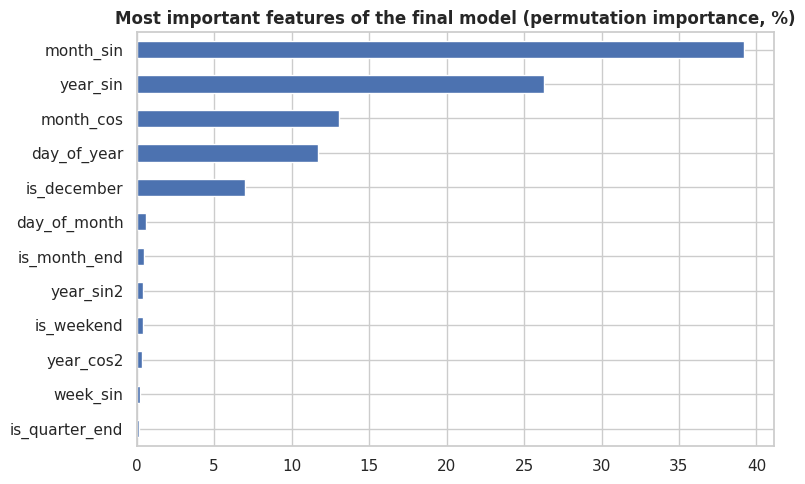

,importance %
month_sin,39.20
year_sin,26.30
month_cos,13.10
day_of_year,11.70
is_december,7.00
day_of_month,0.60
is_month_end,0.50
year_sin2,0.40
is_weekend,0.40
year_cos2,0.40


In [42]:
# Feature importance of the final model (permutation importance on the last 365 days)
from sklearn.inspection import permutation_importance
capped = daily.clip(upper=CAP); Xi = fc.build_frame(capped, W["use_lags"], ORIGIN)[W["cols"]].iloc[-365:]; yi = capped.loc[Xi.index]
pi = permutation_importance(FINAL_MODEL, Xi, yi, n_repeats=8, random_state=SEED, scoring="neg_root_mean_squared_error")
IMP = pd.Series(pi.importances_mean, index=W["cols"]).sort_values(ascending=False)
IMP_PCT = (IMP.clip(lower=0) / IMP.clip(lower=0).sum() * 100) if IMP.clip(lower=0).sum() > 0 else IMP * 0
IMP_PCT.head(12).iloc[::-1].plot.barh(figsize=(8, 5), color="#4C72B0"); plt.title("Most important features of the final model (permutation importance, %)")
plt.tight_layout(); savefig("18_feature_importance"); plt.show(); display(IMP_PCT.head(10).round(1).to_frame("importance %"))

## 14. Save the model (joblib) with versioning
Artifacts written to `api/artifacts/`: `model.joblib` (fitted pipeline), `metadata.json` (version, features, metrics, error bands, importances, leaderboard),
`history.csv` (daily sales – needed by the API for lag features and charts) and `forecast.csv` (the pre-computed 90-day forecast).

In [43]:
ART = "../api/artifacts"
joblib.dump(FINAL_MODEL, f"{ART}/model.joblib", compress=3)
daily.to_frame("sales").to_csv(f"{ART}/history.csv")
fc_df.to_csv(f"{ART}/forecast.csv", index_label="date")
data_hash = hashlib.sha256(open(DATA, "rb").read()).hexdigest()[:12]
best_p = tune_log[[t["model"] for t in tune_log].index(WINNER)]["best_params"]
META = {
 "model_version": "1.0.0", "trained_at": dt.datetime.utcnow().isoformat(timespec="seconds") + "Z", "data_hash": data_hash,
 "model_name": WINNER, "model_params": {k: (list(v) if isinstance(v, tuple) else v) for k, v in best_p.items()},
 "feature_set": W["feature_set"], "use_lags": bool(W["use_lags"]), "features": W["cols"], "origin": str(ORIGIN.date()),
 "cap_value": CAP, "horizon_days": HORIZON, "history_start": str(daily.index.min().date()), "history_end": str(daily.index.max().date()),
 "forecast_start": str(FC.index.min().date()), "forecast_end": str(FC.index.max().date()), "n_training_days": int(len(daily)),
 "validation_metrics": {k: float(FIN.iloc[0][k]) for k in ["RMSE", "WAPE_7d", "WAPE_30d", "Total90_abs"]},
 "test_metrics": RESULTS["test_metrics"], "best_baseline": {k: (float(v) if not isinstance(v, str) else v) for k, v in RESULTS["best_baseline"].items()},
 "intervals": INTERVALS, "feature_importance": {k: float(v) for k, v in IMP_PCT.head(15).items()},
 "leaderboard": cand[["model", "family", "feature_set", "RMSE", "WAPE_7d", "WAPE_30d", "Total90_abs", "score"]].head(15).round(3).to_dict("records"),
 "n_models_compared": RESULTS["n_models"], "inference_seconds_90d": float(pred_t),
 "window_errors": WIN.reset_index().round(2).to_dict("records"),
}
json.dump(META, open(f"{ART}/metadata.json", "w"), indent=2)
print("Saved:", os.listdir(ART), "| model size:", f"{os.path.getsize(f'{ART}/model.joblib') / 1024:.0f} KB")

Saved: ['forecast.csv', 'model.joblib', 'history.csv', 'metadata.json'] | model size: 2 KB


In [44]:
# Sanity check: re-load from disk exactly like the API does and reproduce the forecast
m2 = joblib.load(f"{ART}/model.joblib"); hist2 = pd.read_csv(f"{ART}/history.csv", index_col=0, parse_dates=True)["sales"]
re = fc.forecast(m2, hist2.clip(upper=META["cap_value"]), HORIZON, META["use_lags"], META["features"], pd.Timestamp(META["origin"]), max_value=META["cap_value"])
print("Max difference between notebook forecast and re-loaded model forecast:", float((re - FC).abs().max()))

Max difference between notebook forecast and re-loaded model forecast: 0.0


In [45]:
json.dump({k: v for k, v in RESULTS.items() if k != "feature_ranking"} | {"winner": WINNER, "tune_log": tune_log,
          "final_candidates": FIN.round(3).to_dict("records"), "ablation": AB.round(3).to_dict("records"),
          "forecast_total": float(FC.sum()), "forecast_vs_last_year": float(tot / ly - 1) if ly else None, "last_year_total": float(ly),
          "monthly_forecast": {str(k): float(v) for k, v in monthly_fc.items()}, "feature_ranking": RESULTS["feature_ranking"][:12],
          "feature_set_means": cand.groupby("feature_set")[["RMSE", "WAPE_7d", "Total90_abs"]].mean().round(2).to_dict("index"),
          "baselines_val": base[["model", "RMSE", "R2", "WAPE_7d", "WAPE_30d", "Total90_err"]].round(2).to_dict("records"),
          "test_baselines": {n: {k: float(v) for k, v in m.items()} for n, m in bl_m.items()}, "top15": cand[show].head(15).round(2).to_dict("records")},
          open("../docs/results_summary.json", "w"), indent=2, default=str)

## 15. Deployment (summary)
* **API** – `api/main.py` (FastAPI): `/health`, `/model-info`, `/forecast`, `/forecast/date`, `/history`, `/leaderboard`; input validation, error handling, env-var configuration, versioned model.
* **Docker** – `api/Dockerfile`; **Render** – `render.yaml` (web service from the Dockerfile).
* **UI** – `frontend/app.py` (Streamlit) talks to the API through the `API_URL` environment variable.
* Full commands are in `README.md`.